# 04C FORCE shared class conditional transport bank

> Saved outputs are from an earlier local run. Portable path edits have **not** been re-executed. See the repository README for setup and scientific limitations.


In [1]:
# نصب کتابخانه‌ها در صورت نیاز

import sys
import subprocess
import importlib.util

required_packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "pyarrow": "pyarrow",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing {package_name} ...")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package_name]
        )

print("All required packages are available.")

All required packages are available.


In [2]:
from pathlib import Path
import gc
import hashlib
import json
import math
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 250)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 200)

EPSILON = 1e-12
MONOTONIC_TOLERANCE = 1e-10
np.random.seed(42)

In [3]:
RUN_MODE = "full"  # "pilot" or "full"

PILOT_OUTER_FOLDS = [1]
FULL_OUTER_FOLDS = [1, 2, 3, 4, 5]

ACTIVE_OUTER_FOLDS = (
    PILOT_OUTER_FOLDS
    if RUN_MODE == "pilot"
    else FULL_OUTER_FOLDS
)

PILOT_FEATURES = [
    "GR",
    "RHOB",
    "RDEP",
    "PEF",
    "SP",
]

FULL_FEATURES = [
    "GR",
    "NPHI",
    "RHOB",
    "DTC",
    "RDEP",
    "CALI",
    "PEF",
    "SP",
]

ACTIVE_FEATURES = (
    PILOT_FEATURES
    if RUN_MODE == "pilot"
    else FULL_FEATURES
)

DOSES = [
    0.25,
    0.50,
    0.75,
    1.00,
]

# جفت‌های Pilot به‌صورت جهت‌دار هستند.
PILOT_CLASS_PAIRS = [
    ("Shale", "Limestone"),
    ("Limestone", "Shale"),
    ("Shale", "Sandstone"),
    ("Sandstone", "Shale"),
    ("Shale", "Sandstone/Shale"),
    ("Sandstone/Shale", "Shale"),
    ("Limestone", "Dolomite"),
    ("Dolomite", "Limestone"),
]

# در Full، جفت‌های پیشنهادشده 04B به همراه Limestone ↔ Dolomite استفاده می‌شوند.
ADDITIONAL_FULL_PAIRS = [
    ("Limestone", "Dolomite"),
    ("Dolomite", "Limestone"),
]

ALLOW_DESCRIPTIVE_CONDITIONS = False
SKIP_COMPLETED_CONDITIONS = True
SAVE_CONDITION_BANKS = True

MAX_CONDITION_DIAGNOSTIC_PLOTS = 12
MAX_SAMPLE_TRAJECTORIES_PER_PLOT = 40
RANDOM_STATE_FOR_PLOTS = 42

# Portable project paths (independent of machine-specific Desktop folders).
import os

def _find_stratashift_root():
    start = Path(os.environ.get("STRATASHIFT_REPO_ROOT", Path.cwd())).expanduser().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "notebooks" / "interventions").is_dir() and (candidate / "README.md").is_file():
            return candidate
    raise FileNotFoundError(
        "StrataShift repository root not found. Open Jupyter from inside the repo "
        "or set STRATASHIFT_REPO_ROOT to its absolute path."
    )

REPO_ROOT = _find_stratashift_root()
TRAIN_PATH = Path(os.environ.get(
    "STRATASHIFT_TRAIN_CSV", str(REPO_ROOT / "data" / "raw" / "train.csv")
)).expanduser().resolve()
PROJECT_ROOT = Path(os.environ.get(
    "STRATASHIFT_ARTIFACT_ROOT", str(REPO_ROOT / "artifacts")
)).expanduser().resolve()


STAGE_01_DIR = (
    PROJECT_ROOT
    / "01_clean_splits_support"
)

FOLD_ASSIGNMENT_PATH = (
    STAGE_01_DIR
    / "10_grouped_5fold_well_assignment.csv"
)

STAGE_04B_DIR = (
    PROJECT_ROOT
    / "04B_class_pair_support_transport_registry"
    / "full"
)

PAIR_REGISTRY_PATH = (
    STAGE_04B_DIR
    / "05_directed_pair_support_registry.csv"
)

PAIR_STABILITY_PATH = (
    STAGE_04B_DIR
    / "06_pair_stability_summary.csv"
)

RECOMMENDED_PAIR_PATH = (
    STAGE_04B_DIR
    / "10_recommended_pilot_pairs.csv"
)

STAGE_04B_GATE_PATH = (
    STAGE_04B_DIR
    / "13_registry_gate.json"
)

STAGE_04B_CONFIG_PATH = (
    STAGE_04B_DIR
    / "14_run_configuration.json"
)

OUTPUT_ROOT = (
    PROJECT_ROOT
    / "04C_shared_class_conditional_transport_bank"
)

OUTPUT_DIR = (
    OUTPUT_ROOT
    / RUN_MODE
)

BANK_DIR = (
    OUTPUT_DIR
    / "transport_bank"
)

PLOT_DIR = (
    OUTPUT_DIR
    / "plots"
)

for directory in [
    OUTPUT_ROOT,
    OUTPUT_DIR,
    BANK_DIR,
    PLOT_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

SENTINEL_VALUES = {
    "SP": [-999.0],
}

LOG_SPACE_FEATURES = {
    "RDEP",
}

required_paths = [
    TRAIN_PATH,
    FOLD_ASSIGNMENT_PATH,
    PAIR_REGISTRY_PATH,
    PAIR_STABILITY_PATH,
    RECOMMENDED_PAIR_PATH,
    STAGE_04B_GATE_PATH,
    STAGE_04B_CONFIG_PATH,
]

missing_paths = [
    str(path)
    for path in required_paths
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Required inputs are missing:\n"
        + "\n".join(missing_paths)
    )

print("RUN_MODE:", RUN_MODE)
print("Outer folds:", ACTIVE_OUTER_FOLDS)
print("Features:", ACTIVE_FEATURES)
print("Doses:", DOSES)
print("Output:", OUTPUT_DIR)

RUN_MODE: full
Outer folds: [1, 2, 3, 4, 5]
Features: ['GR', 'NPHI', 'RHOB', 'DTC', 'RDEP', 'CALI', 'PEF', 'SP']
Doses: [0.25, 0.5, 0.75, 1.0]
Output: ${STRATASHIFT_ARTIFACT_ROOT}/04C_shared_class_conditional_transport_bank/full


In [4]:
with open(
    STAGE_04B_GATE_PATH,
    "r",
    encoding="utf-8",
) as file:
    stage_04b_gate = json.load(file)

with open(
    STAGE_04B_CONFIG_PATH,
    "r",
    encoding="utf-8",
) as file:
    stage_04b_config = json.load(file)

stage_04b_audit = {
    "stage_04b_passed": bool(
        stage_04b_gate.get(
            "overall_registry_passed",
            False,
        )
    ),
    "stage_04b_official_test_unused": bool(
        stage_04b_gate.get(
            "official_test_unused",
            False,
        )
    ),
    "stage_04b_full_run": (
        stage_04b_config.get(
            "run_mode"
        )
        == "full"
    ),
    "stage_04b_mapping_from_outer_training_only": (
        stage_04b_config.get(
            "transport_mapping_source"
        )
        == "outer-training wells only"
    ),
}

print(
    json.dumps(
        stage_04b_audit,
        indent=2,
    )
)

if not all(
    stage_04b_audit.values()
):
    raise RuntimeError(
        "Stage 04B audit failed."
    )

{
  "stage_04b_passed": true,
  "stage_04b_official_test_unused": true,
  "stage_04b_full_run": true,
  "stage_04b_mapping_from_outer_training_only": true
}


In [5]:
def detect_csv_format(
    file_path,
    num_lines=5,
):
    encodings = [
        "utf-8",
        "latin1",
        "iso-8859-1",
        "cp1252",
    ]

    for encoding in encodings:
        try:
            with open(
                file_path,
                "r",
                encoding=encoding,
            ) as file:
                first_lines = [
                    file.readline()
                    for _ in range(num_lines)
                ]

            if any(
                "," in line
                for line in first_lines
            ):
                delimiter = ","
            elif any(
                ";" in line
                for line in first_lines
            ):
                delimiter = ";"
            elif any(
                "\t" in line
                for line in first_lines
            ):
                delimiter = "\t"
            else:
                delimiter = ","

            return {
                "sep": delimiter,
                "encoding": encoding,
            }

        except UnicodeDecodeError:
            continue

    return {
        "sep": ",",
        "encoding": "utf-8",
    }


csv_format = detect_csv_format(
    TRAIN_PATH
)

train_raw = pd.read_csv(
    TRAIN_PATH,
    sep=csv_format["sep"],
    encoding=csv_format["encoding"],
    low_memory=False,
)

train_raw[
    "ORIGINAL_ROW_ID"
] = np.arange(
    len(train_raw),
    dtype=np.int64,
)

fold_assignment_raw = pd.read_csv(
    FOLD_ASSIGNMENT_PATH
)

well_candidates = [
    column
    for column
    in fold_assignment_raw.columns
    if column.upper() == "WELL"
]

fold_candidates = [
    column
    for column
    in fold_assignment_raw.columns
    if (
        "FOLD" in column.upper()
        and "SCORE" not in column.upper()
    )
]

if not well_candidates or not fold_candidates:
    raise ValueError(
        "Could not infer WELL/FOLD columns."
    )

fold_assignment = (
    fold_assignment_raw[
        [
            well_candidates[0],
            fold_candidates[0],
        ]
    ]
    .rename(
        columns={
            well_candidates[0]: "WELL",
            fold_candidates[0]: "GROUP_FOLD",
        }
    )
    .drop_duplicates(
        subset=["WELL"]
    )
    .copy()
)

fold_assignment[
    "GROUP_FOLD"
] = pd.to_numeric(
    fold_assignment[
        "GROUP_FOLD"
    ],
    errors="raise",
).astype(int)

well_to_fold = dict(
    zip(
        fold_assignment["WELL"],
        fold_assignment["GROUP_FOLD"],
    )
)

train_raw[
    "GROUP_FOLD"
] = train_raw[
    "WELL"
].map(
    well_to_fold
)

if train_raw[
    "GROUP_FOLD"
].isna().any():
    raise RuntimeError(
        "Some train wells do not have a grouped-fold assignment."
    )

train_raw[
    "GROUP_FOLD"
] = train_raw[
    "GROUP_FOLD"
].astype(int)

pair_registry = pd.read_csv(
    PAIR_REGISTRY_PATH
)

pair_stability = pd.read_csv(
    PAIR_STABILITY_PATH
)

recommended_pairs_04b = pd.read_csv(
    RECOMMENDED_PAIR_PATH
)

print("Train shape:", train_raw.shape)
print("Pair registry shape:", pair_registry.shape)
print("Recommended pairs shape:", recommended_pairs_04b.shape)

Train shape: (1170511, 31)
Pair registry shape: (5280, 23)
Recommended pairs shape: (48, 23)


In [6]:
TARGET_COLUMN = (
    "FORCE_2020_LITHOFACIES_LITHOLOGY"
)

LITHOLOGY_CODES = sorted([
    30000,
    65030,
    65000,
    80000,
    74000,
    70000,
    70032,
    88000,
    86000,
    99000,
    90000,
    93000,
])

LITHOLOGY_NAMES = {
    30000: "Sandstone",
    65000: "Shale",
    65030: "Sandstone/Shale",
    70000: "Limestone",
    70032: "Chalk",
    74000: "Dolomite",
    80000: "Marl",
    86000: "Anhydrite",
    88000: "Halite",
    90000: "Coal",
    93000: "Basement",
    99000: "Tuff",
}

NAME_TO_CODE = {
    name: code
    for code, name
    in LITHOLOGY_NAMES.items()
}

missing_features = [
    feature
    for feature in ACTIVE_FEATURES
    if feature not in train_raw.columns
]

if missing_features:
    raise KeyError(
        "Missing features in train.csv: "
        f"{missing_features}"
    )

train_raw[
    "LITHOLOGY_CODE"
] = pd.to_numeric(
    train_raw[
        TARGET_COLUMN
    ],
    errors="coerce",
).astype("Int64")

train_raw[
    "LITHOLOGY_NAME"
] = train_raw[
    "LITHOLOGY_CODE"
].map(
    LITHOLOGY_NAMES
)


def clean_feature_series(
    dataframe,
    feature,
):
    values = pd.to_numeric(
        dataframe[feature],
        errors="coerce",
    ).astype(float)

    sentinel_mask = np.zeros(
        len(values),
        dtype=bool,
    )

    for sentinel in SENTINEL_VALUES.get(
        feature,
        [],
    ):
        sentinel_mask |= np.isclose(
            values.to_numpy(
                dtype=float
            ),
            sentinel,
            rtol=0.0,
            atol=1e-12,
            equal_nan=False,
        )

    values.loc[
        sentinel_mask
    ] = np.nan

    nonfinite_mask = (
        ~np.isfinite(
            values.to_numpy(
                dtype=float
            )
        )
    )

    values.loc[
        nonfinite_mask
    ] = np.nan

    nonpositive_mask = np.zeros(
        len(values),
        dtype=bool,
    )

    if feature in LOG_SPACE_FEATURES:
        nonpositive_mask = (
            values.to_numpy(
                dtype=float
            )
            <= 0
        ) & values.notna().to_numpy()

        values.loc[
            nonpositive_mask
        ] = np.nan

    return {
        "values": values,
        "sentinel_mask": sentinel_mask,
        "nonfinite_mask": nonfinite_mask,
        "nonpositive_mask": nonpositive_mask,
    }

In [7]:
cleaning_audit_rows = []

for feature in ACTIVE_FEATURES:
    cleaned = clean_feature_series(
        train_raw,
        feature,
    )

    original_numeric = pd.to_numeric(
        train_raw[feature],
        errors="coerce",
    )

    cleaning_audit_rows.append({
        "feature": feature,
        "rows": int(
            len(train_raw)
        ),
        "raw_numeric_rows": int(
            original_numeric.notna().sum()
        ),
        "sentinel_rows": int(
            cleaned[
                "sentinel_mask"
            ].sum()
        ),
        "nonfinite_rows": int(
            cleaned[
                "nonfinite_mask"
            ].sum()
        ),
        "nonpositive_rows_removed_for_log_space": int(
            cleaned[
                "nonpositive_mask"
            ].sum()
        ),
        "clean_observed_rows": int(
            cleaned[
                "values"
            ].notna().sum()
        ),
        "clean_missing_rate": float(
            cleaned[
                "values"
            ].isna().mean()
        ),
        "transport_space": (
            "log"
            if feature
            in LOG_SPACE_FEATURES
            else "linear"
        ),
    })

cleaning_audit = pd.DataFrame(
    cleaning_audit_rows
)

display(cleaning_audit)

,feature,rows,raw_numeric_rows,sentinel_rows,nonfinite_rows,nonpositive_rows_removed_for_log_space,clean_observed_rows,clean_missing_rate,transport_space
0,GR,1170511,1170511,0,0,0,1170511,0.000000,linear
1,NPHI,1170511,765409,0,405102,0,765409,0.346090,linear
2,RHOB,1170511,1009242,0,161269,0,1009242,0.137777,linear
3,DTC,1170511,1089648,0,80863,0,1089648,0.069084,linear
4,RDEP,1170511,1159496,0,11015,0,1159496,0.009410,log
5,CALI,1170511,1082634,0,87877,0,1082634,0.075076,linear
6,PEF,1170511,671692,0,498819,0,671692,0.426155,linear
7,SP,1170511,864247,402,306666,0,863845,0.261993,linear


In [8]:
def pair_name_to_codes(
    source_name,
    target_name,
):
    return (
        NAME_TO_CODE[
            source_name
        ],
        NAME_TO_CODE[
            target_name
        ],
    )


if RUN_MODE == "pilot":
    requested_pairs = (
        pd.DataFrame(
            PILOT_CLASS_PAIRS,
            columns=[
                "source_name",
                "target_name",
            ],
        )
        .drop_duplicates()
        .reset_index(drop=True)
    )
else:
    recommended_columns = [
        "source_name",
        "target_name",
    ]

    requested_pairs = (
        recommended_pairs_04b[
            recommended_columns
        ]
        .drop_duplicates()
        .copy()
    )

    additional_pairs_df = pd.DataFrame(
        ADDITIONAL_FULL_PAIRS,
        columns=[
            "source_name",
            "target_name",
        ],
    )

    requested_pairs = (
        pd.concat(
            [
                requested_pairs,
                additional_pairs_df,
            ],
            ignore_index=True,
        )
        .drop_duplicates()
        .reset_index(drop=True)
    )

requested_pairs[
    "source_code"
] = requested_pairs[
    "source_name"
].map(
    NAME_TO_CODE
)

requested_pairs[
    "target_code"
] = requested_pairs[
    "target_name"
].map(
    NAME_TO_CODE
)

if requested_pairs[
    [
        "source_code",
        "target_code",
    ]
].isna().any().any():
    raise ValueError(
        "Unknown class name in requested pair list."
    )

requested_pairs[
    "source_code"
] = requested_pairs[
    "source_code"
].astype(int)

requested_pairs[
    "target_code"
] = requested_pairs[
    "target_code"
].astype(int)

display(requested_pairs)

,source_name,target_name,source_code,target_code
0,Shale,Limestone,65000,70000
1,Limestone,Shale,70000,65000
2,Shale,Sandstone,65000,30000
3,Sandstone,Shale,30000,65000
4,Shale,Sandstone/Shale,65000,65030
5,Sandstone/Shale,Shale,65030,65000
6,Limestone,Dolomite,70000,74000
7,Dolomite,Limestone,74000,70000


In [9]:
PERCENTILE_MIN = 0.001
PERCENTILE_MAX = 0.999


def empirical_midrank_percentile(
    sorted_training_values,
    query_values,
):
    sorted_training_values = np.asarray(
        sorted_training_values,
        dtype=float,
    )

    query_values = np.asarray(
        query_values,
        dtype=float,
    )

    if sorted_training_values.size == 0:
        raise ValueError(
            "Empty source training distribution."
        )

    left = np.searchsorted(
        sorted_training_values,
        query_values,
        side="left",
    )

    right = np.searchsorted(
        sorted_training_values,
        query_values,
        side="right",
    )

    midrank = (
        left
        + right
    ) / 2.0

    percentiles = (
        midrank
        / sorted_training_values.size
    )

    return np.clip(
        percentiles,
        PERCENTILE_MIN,
        PERCENTILE_MAX,
    )


def target_quantile_values(
    target_training_values,
    percentiles,
):
    target_training_values = np.asarray(
        target_training_values,
        dtype=float,
    )

    percentiles = np.asarray(
        percentiles,
        dtype=float,
    )

    if target_training_values.size == 0:
        raise ValueError(
            "Empty target training distribution."
        )

    return np.quantile(
        target_training_values,
        percentiles,
    )


def make_dose_values(
    original_values,
    target_values,
    feature,
    doses,
):
    original_values = np.asarray(
        original_values,
        dtype=float,
    )

    target_values = np.asarray(
        target_values,
        dtype=float,
    )

    output = {}

    if feature in LOG_SPACE_FEATURES:
        if (
            np.any(
                original_values
                <= 0
            )
            or np.any(
                target_values
                <= 0
            )
        ):
            raise ValueError(
                f"{feature} requires positive values for log-space transport."
            )

        original_log = np.log(
            original_values
        )

        target_log = np.log(
            target_values
        )

        for dose in doses:
            intervened = np.exp(
                (
                    1.0
                    - dose
                )
                * original_log
                + dose
                * target_log
            )

            output[
                dose
            ] = intervened
    else:
        for dose in doses:
            intervened = (
                (
                    1.0
                    - dose
                )
                * original_values
                + dose
                * target_values
            )

            output[
                dose
            ] = intervened

    return output


def dose_column_name(
    dose,
):
    return (
        "value_alpha_"
        + f"{dose:.2f}".replace(
            ".",
            "_",
        )
    )


def safe_file_component(
    value,
):
    return (
        str(value)
        .replace(
            "/",
            "_",
        )
        .replace(
            " ",
            "_",
        )
        .replace(
            "\\",
            "_",
        )
    )


def sha256_file(
    file_path,
    chunk_size=1024 * 1024,
):
    digest = hashlib.sha256()

    with open(
        file_path,
        "rb",
    ) as file:
        while True:
            chunk = file.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(
                chunk
            )

    return digest.hexdigest()

In [10]:
# Thresholdهای 04B را از فایل Configuration می‌خوانیم.
confirmatory_policy = (
    stage_04b_config[
        "confirmatory_policy"
    ]
)

descriptive_policy = (
    stage_04b_config[
        "descriptive_policy"
    ]
)

condition_registry_rows = []

for outer_fold in ACTIVE_OUTER_FOLDS:
    outer_train = train_raw.loc[
        train_raw[
            "GROUP_FOLD"
        ]
        != outer_fold
    ]

    outer_validation = train_raw.loc[
        train_raw[
            "GROUP_FOLD"
        ]
        == outer_fold
    ]

    for feature in ACTIVE_FEATURES:
        train_clean = clean_feature_series(
            outer_train,
            feature,
        )["values"]

        validation_clean = clean_feature_series(
            outer_validation,
            feature,
        )["values"]

        for _, requested_pair in requested_pairs.iterrows():
            source_code = int(
                requested_pair[
                    "source_code"
                ]
            )

            target_code = int(
                requested_pair[
                    "target_code"
                ]
            )

            source_name = requested_pair[
                "source_name"
            ]

            target_name = requested_pair[
                "target_name"
            ]

            original_registry_match = (
                pair_registry.loc[
                    (
                        pair_registry[
                            "outer_fold"
                        ]
                        == outer_fold
                    )
                    & (
                        pair_registry[
                            "feature"
                        ]
                        == feature
                    )
                    & (
                        pair_registry[
                            "source_code"
                        ]
                        == source_code
                    )
                    & (
                        pair_registry[
                            "target_code"
                        ]
                        == target_code
                    )
                ]
            )

            if original_registry_match.empty:
                raise RuntimeError(
                    "Requested condition absent from 04B registry: "
                    f"fold={outer_fold}, feature={feature}, "
                    f"{source_name}->{target_name}"
                )

            original_registry_tier = (
                original_registry_match.iloc[0][
                    "analysis_tier"
                ]
            )

            source_train_mask = (
                outer_train[
                    "LITHOLOGY_CODE"
                ]
                == source_code
            ) & train_clean.notna()

            target_train_mask = (
                outer_train[
                    "LITHOLOGY_CODE"
                ]
                == target_code
            ) & train_clean.notna()

            source_validation_mask = (
                outer_validation[
                    "LITHOLOGY_CODE"
                ]
                == source_code
            ) & validation_clean.notna()

            source_train_rows = int(
                source_train_mask.sum()
            )

            target_train_rows = int(
                target_train_mask.sum()
            )

            source_validation_rows = int(
                source_validation_mask.sum()
            )

            source_train_wells = int(
                outer_train.loc[
                    source_train_mask,
                    "WELL",
                ].nunique()
            )

            target_train_wells = int(
                outer_train.loc[
                    target_train_mask,
                    "WELL",
                ].nunique()
            )

            source_validation_wells = int(
                outer_validation.loc[
                    source_validation_mask,
                    "WELL",
                ].nunique()
            )

            source_train_values = (
                train_clean.loc[
                    source_train_mask
                ]
                .to_numpy(
                    dtype=float
                )
            )

            target_train_values = (
                train_clean.loc[
                    target_train_mask
                ]
                .to_numpy(
                    dtype=float
                )
            )

            source_unique = int(
                np.unique(
                    source_train_values
                ).size
            )

            target_unique = int(
                np.unique(
                    target_train_values
                ).size
            )

            source_iqr = (
                float(
                    np.quantile(
                        source_train_values,
                        0.75,
                    )
                    - np.quantile(
                        source_train_values,
                        0.25,
                    )
                )
                if source_train_rows > 0
                else np.nan
            )

            target_iqr = (
                float(
                    np.quantile(
                        target_train_values,
                        0.75,
                    )
                    - np.quantile(
                        target_train_values,
                        0.25,
                    )
                )
                if target_train_rows > 0
                else np.nan
            )

            confirmatory_after_cleaning = bool(
                source_train_rows
                >= confirmatory_policy[
                    "minimum_train_observed_rows_per_class"
                ]
                and target_train_rows
                >= confirmatory_policy[
                    "minimum_train_observed_rows_per_class"
                ]
                and source_train_wells
                >= confirmatory_policy[
                    "minimum_train_observed_wells_per_class"
                ]
                and target_train_wells
                >= confirmatory_policy[
                    "minimum_train_observed_wells_per_class"
                ]
                and source_validation_rows
                >= confirmatory_policy[
                    "minimum_source_validation_observed_rows"
                ]
                and source_validation_wells
                >= confirmatory_policy[
                    "minimum_source_validation_observed_wells"
                ]
                and source_unique >= 10
                and target_unique >= 10
                and np.isfinite(
                    source_iqr
                )
                and np.isfinite(
                    target_iqr
                )
                and source_iqr > EPSILON
                and target_iqr > EPSILON
            )

            descriptive_after_cleaning = bool(
                (
                    not confirmatory_after_cleaning
                )
                and source_train_rows
                >= descriptive_policy[
                    "minimum_train_observed_rows_per_class"
                ]
                and target_train_rows
                >= descriptive_policy[
                    "minimum_train_observed_rows_per_class"
                ]
                and source_train_wells
                >= descriptive_policy[
                    "minimum_train_observed_wells_per_class"
                ]
                and target_train_wells
                >= descriptive_policy[
                    "minimum_train_observed_wells_per_class"
                ]
                and source_validation_rows
                >= descriptive_policy[
                    "minimum_source_validation_observed_rows"
                ]
                and source_validation_wells
                >= descriptive_policy[
                    "minimum_source_validation_observed_wells"
                ]
                and source_unique >= 10
                and target_unique >= 10
                and np.isfinite(
                    source_iqr
                )
                and np.isfinite(
                    target_iqr
                )
                and source_iqr > EPSILON
                and target_iqr > EPSILON
            )

            if confirmatory_after_cleaning:
                cleaned_tier = (
                    "confirmatory"
                )
            elif descriptive_after_cleaning:
                cleaned_tier = (
                    "descriptive"
                )
            else:
                cleaned_tier = (
                    "not_estimable"
                )

            selected_for_bank = bool(
                cleaned_tier
                == "confirmatory"
                or (
                    ALLOW_DESCRIPTIVE_CONDITIONS
                    and cleaned_tier
                    == "descriptive"
                )
            )

            condition_registry_rows.append({
                "outer_fold": outer_fold,
                "feature": feature,
                "source_code": source_code,
                "source_name": source_name,
                "target_code": target_code,
                "target_name": target_name,
                "original_04B_tier": (
                    original_registry_tier
                ),
                "cleaned_tier": (
                    cleaned_tier
                ),
                "selected_for_bank": (
                    selected_for_bank
                ),
                "source_train_rows": (
                    source_train_rows
                ),
                "source_train_wells": (
                    source_train_wells
                ),
                "target_train_rows": (
                    target_train_rows
                ),
                "target_train_wells": (
                    target_train_wells
                ),
                "source_validation_rows": (
                    source_validation_rows
                ),
                "source_validation_wells": (
                    source_validation_wells
                ),
                "source_unique_values": (
                    source_unique
                ),
                "target_unique_values": (
                    target_unique
                ),
                "source_iqr": source_iqr,
                "target_iqr": target_iqr,
                "transport_space": (
                    "log"
                    if feature
                    in LOG_SPACE_FEATURES
                    else "linear"
                ),
            })

    del outer_train, outer_validation
    gc.collect()

condition_registry = pd.DataFrame(
    condition_registry_rows
)

display(
    condition_registry.head(40)
)

print(
    condition_registry[
        [
            "cleaned_tier",
            "selected_for_bank",
        ]
    ].value_counts()
)

,outer_fold,feature,source_code,source_name,target_code,target_name,original_04B_tier,cleaned_tier,selected_for_bank,source_train_rows,source_train_wells,target_train_rows,target_train_wells,source_validation_rows,source_validation_wells,source_unique_values,target_unique_values,source_iqr,target_iqr,transport_space
0,1,GR,65000,Shale,70000,Limestone,confirmatory,confirmatory,True,577302,78,46089,75,143501,20,565192,46046,35.636568,36.271624,linear
1,1,GR,70000,Limestone,65000,Shale,confirmatory,confirmatory,True,46089,75,577302,78,10231,19,46046,565192,36.271624,35.636568,linear
2,1,GR,65000,Shale,30000,Sandstone,confirmatory,confirmatory,True,577302,78,136649,78,143501,20,565192,136144,35.636568,30.086361,linear
3,1,GR,30000,Sandstone,65000,Shale,confirmatory,confirmatory,True,136649,78,577302,78,32288,20,136144,565192,30.086361,35.636568,linear
4,1,GR,65000,Shale,65030,Sandstone/Shale,confirmatory,confirmatory,True,577302,78,123799,77,143501,20,565192,123325,35.636568,32.799898,linear
5,1,GR,65030,Sandstone/Shale,65000,Shale,confirmatory,confirmatory,True,123799,77,577302,78,26656,20,123325,565192,32.799898,35.636568,linear
6,1,GR,70000,Limestone,74000,Dolomite,confirmatory,confirmatory,True,46089,75,1398,30,10231,19,46046,1398,36.271624,34.534328,linear
7,1,GR,74000,Dolomite,70000,Limestone,confirmatory,confirmatory,True,1398,30,46089,75,290,7,1398,46046,34.534328,36.271624,linear
8,1,NPHI,65000,Shale,70000,Limestone,confirmatory,confirmatory,True,366760,78,31892,73,96664,20,353894,31657,0.163898,0.115864,linear
9,1,NPHI,70000,Limestone,65000,Shale,confirmatory,confirmatory,True,31892,73,366760,78,8345,19,31657,353894,0.115864,0.163898,linear


cleaned_tier  selected_for_bank
confirmatory  True                 319
descriptive   False                  1
Name: count, dtype: int64


In [11]:
condition_summary_rows = []
condition_manifest_rows = []
per_well_shift_frames = []

selected_conditions = (
    condition_registry.loc[
        condition_registry[
            "selected_for_bank"
        ]
        == True
    ]
    .sort_values(
        [
            "outer_fold",
            "feature",
            "source_code",
            "target_code",
        ]
    )
    .reset_index(drop=True)
)

print(
    "Selected condition count:",
    len(
        selected_conditions
    ),
)

for condition_index, condition in selected_conditions.iterrows():
    outer_fold = int(
        condition[
            "outer_fold"
        ]
    )

    feature = condition[
        "feature"
    ]

    source_code = int(
        condition[
            "source_code"
        ]
    )

    source_name = condition[
        "source_name"
    ]

    target_code = int(
        condition[
            "target_code"
        ]
    )

    target_name = condition[
        "target_name"
    ]

    condition_id = (
        f"fold_{outer_fold}"
        f"__feature_{safe_file_component(feature)}"
        f"__source_{source_code}_{safe_file_component(source_name)}"
        f"__target_{target_code}_{safe_file_component(target_name)}"
    )

    bank_path = (
        BANK_DIR
        / f"{condition_id}.parquet"
    )

    summary_path = (
        BANK_DIR
        / f"{condition_id}__summary.json"
    )

    completed = bool(
        bank_path.exists()
        and summary_path.exists()
    )

    if (
        SKIP_COMPLETED_CONDITIONS
        and completed
    ):
        print(
            f"[cache] {condition_id}"
        )

        with open(
            summary_path,
            "r",
            encoding="utf-8",
        ) as file:
            condition_summary = json.load(
                file
            )

        condition_summary_rows.append(
            condition_summary
        )

        cached_bank = pd.read_parquet(
            bank_path
        )

        per_well_shift = (
            cached_bank.groupby(
                "WELL",
                as_index=False,
            )
            .agg(
                eligible_rows=(
                    "ORIGINAL_ROW_ID",
                    "size",
                ),
                mean_abs_full_transport_shift=(
                    "absolute_full_transport_shift",
                    "mean",
                ),
                median_abs_full_transport_shift=(
                    "absolute_full_transport_shift",
                    "median",
                ),
                mean_normalized_full_transport_shift=(
                    "normalized_full_transport_shift",
                    "mean",
                ),
            )
        )

        per_well_shift[
            "outer_fold"
        ] = outer_fold

        per_well_shift[
            "feature"
        ] = feature

        per_well_shift[
            "source_code"
        ] = source_code

        per_well_shift[
            "source_name"
        ] = source_name

        per_well_shift[
            "target_code"
        ] = target_code

        per_well_shift[
            "target_name"
        ] = target_name

        per_well_shift_frames.append(
            per_well_shift
        )

        condition_manifest_rows.append({
            "condition_id": condition_id,
            "outer_fold": outer_fold,
            "feature": feature,
            "source_name": source_name,
            "target_name": target_name,
            "status": "loaded_from_cache",
            "bank_path": str(
                bank_path
            ),
            "summary_path": str(
                summary_path
            ),
            "bank_sha256": sha256_file(
                bank_path
            ),
        })

        del cached_bank, per_well_shift
        gc.collect()
        continue

    print(
        f"[build {condition_index + 1}/{len(selected_conditions)}] "
        f"{condition_id}"
    )

    start_time = time.time()

    outer_train = train_raw.loc[
        train_raw[
            "GROUP_FOLD"
        ]
        != outer_fold
    ].copy()

    outer_validation = train_raw.loc[
        train_raw[
            "GROUP_FOLD"
        ]
        == outer_fold
    ].copy()

    train_clean = clean_feature_series(
        outer_train,
        feature,
    )["values"]

    validation_clean = clean_feature_series(
        outer_validation,
        feature,
    )["values"]

    source_train_mask = (
        outer_train[
            "LITHOLOGY_CODE"
        ]
        == source_code
    ) & train_clean.notna()

    target_train_mask = (
        outer_train[
            "LITHOLOGY_CODE"
        ]
        == target_code
    ) & train_clean.notna()

    source_validation_mask = (
        outer_validation[
            "LITHOLOGY_CODE"
        ]
        == source_code
    ) & validation_clean.notna()

    source_training_values = np.sort(
        train_clean.loc[
            source_train_mask
        ]
        .to_numpy(
            dtype=float
        )
    )

    target_training_values = np.sort(
        train_clean.loc[
            target_train_mask
        ]
        .to_numpy(
            dtype=float
        )
    )

    eligible_validation = (
        outer_validation.loc[
            source_validation_mask,
            [
                "ORIGINAL_ROW_ID",
                "WELL",
                "DEPTH_MD",
                "LITHOLOGY_CODE",
                "LITHOLOGY_NAME",
            ],
        ]
        .copy()
        .reset_index(drop=True)
    )

    original_values = (
        validation_clean.loc[
            source_validation_mask
        ]
        .to_numpy(
            dtype=float
        )
    )

    source_percentiles = (
        empirical_midrank_percentile(
            source_training_values,
            original_values,
        )
    )

    target_values = (
        target_quantile_values(
            target_training_values,
            source_percentiles,
        )
    )

    dose_values = make_dose_values(
        original_values=(
            original_values
        ),
        target_values=(
            target_values
        ),
        feature=feature,
        doses=DOSES,
    )

    bank = eligible_validation

    bank[
        "outer_fold"
    ] = outer_fold

    bank[
        "feature"
    ] = feature

    bank[
        "source_code"
    ] = source_code

    bank[
        "source_name"
    ] = source_name

    bank[
        "target_code"
    ] = target_code

    bank[
        "target_name"
    ] = target_name

    bank[
        "transport_space"
    ] = (
        "log"
        if feature
        in LOG_SPACE_FEATURES
        else "linear"
    )

    bank[
        "original_value"
    ] = original_values.astype(
        np.float64
    )

    bank[
        "source_percentile"
    ] = source_percentiles.astype(
        np.float64
    )

    bank[
        "target_quantile_value"
    ] = target_values.astype(
        np.float64
    )

    bank[
        "full_transport_shift"
    ] = (
        target_values
        - original_values
    ).astype(
        np.float64
    )

    bank[
        "absolute_full_transport_shift"
    ] = np.abs(
        target_values
        - original_values
    ).astype(
        np.float64
    )

    pooled_iqr = max(
        (
            float(
                condition[
                    "source_iqr"
                ]
            )
            + float(
                condition[
                    "target_iqr"
                ]
            )
        )
        / 2.0,
        EPSILON,
    )

    bank[
        "normalized_full_transport_shift"
    ] = (
        bank[
            "absolute_full_transport_shift"
        ]
        / pooled_iqr
    ).astype(
        np.float64
    )

    for dose in DOSES:
        bank[
            dose_column_name(
                dose
            )
        ] = dose_values[
            dose
        ].astype(
            np.float64
        )

    # ---------------------------------------------
    # Condition-level validation
    # ---------------------------------------------

    sorted_order = np.argsort(
        bank[
            "original_value"
        ].to_numpy()
    )

    sorted_target = bank[
        "target_quantile_value"
    ].to_numpy()[
        sorted_order
    ]

    monotonic_violations = int(
        np.sum(
            np.diff(
                sorted_target
            )
            < -MONOTONIC_TOLERANCE
        )
    )

    alpha_one_difference = float(
        np.max(
            np.abs(
                bank[
                    dose_column_name(
                        1.00
                    )
                ].to_numpy()
                - bank[
                    "target_quantile_value"
                ].to_numpy()
            )
        )
    )

    endpoint_min = np.minimum(
        original_values,
        target_values,
    )

    endpoint_max = np.maximum(
        original_values,
        target_values,
    )

    dose_between_endpoint_flags = []

    for dose in DOSES:
        dose_array = bank[
            dose_column_name(
                dose
            )
        ].to_numpy(
            dtype=float
        )

        dose_between_endpoint_flags.append(
            bool(
                np.all(
                    dose_array
                    >= endpoint_min
                    - MONOTONIC_TOLERANCE
                )
                and np.all(
                    dose_array
                    <= endpoint_max
                    + MONOTONIC_TOLERANCE
                )
            )
        )

    percentiles_in_range = bool(
        (
            bank[
                "source_percentile"
            ]
            >= PERCENTILE_MIN
        ).all()
        and (
            bank[
                "source_percentile"
            ]
            <= PERCENTILE_MAX
        ).all()
    )

    target_train_min = float(
        np.min(
            target_training_values
        )
    )

    target_train_max = float(
        np.max(
            target_training_values
        )
    )

    target_values_in_training_range = bool(
        (
            target_values
            >= target_train_min
            - MONOTONIC_TOLERANCE
        ).all()
        and (
            target_values
            <= target_train_max
            + MONOTONIC_TOLERANCE
        ).all()
    )

    unique_row_ids = bool(
        not bank[
            "ORIGINAL_ROW_ID"
        ].duplicated().any()
    )

    source_labels_correct = bool(
        (
            bank[
                "LITHOLOGY_CODE"
            ]
            == source_code
        ).all()
    )

    finite_all_values = bool(
        np.isfinite(
            bank[
                [
                    "original_value",
                    "source_percentile",
                    "target_quantile_value",
                ]
                + [
                    dose_column_name(
                        dose
                    )
                    for dose
                    in DOSES
                ]
            ].to_numpy(
                dtype=float
            )
        ).all()
    )

    condition_passed = bool(
        monotonic_violations == 0
        and alpha_one_difference
        <= MONOTONIC_TOLERANCE
        and all(
            dose_between_endpoint_flags
        )
        and percentiles_in_range
        and target_values_in_training_range
        and unique_row_ids
        and source_labels_correct
        and finite_all_values
    )

    condition_summary = {
        "condition_id": condition_id,
        "outer_fold": outer_fold,
        "feature": feature,
        "source_code": source_code,
        "source_name": source_name,
        "target_code": target_code,
        "target_name": target_name,
        "cleaned_tier": condition[
            "cleaned_tier"
        ],
        "transport_space": (
            "log"
            if feature
            in LOG_SPACE_FEATURES
            else "linear"
        ),
        "eligible_rows": int(
            len(
                bank
            )
        ),
        "eligible_wells": int(
            bank[
                "WELL"
            ].nunique()
        ),
        "source_training_rows": int(
            len(
                source_training_values
            )
        ),
        "target_training_rows": int(
            len(
                target_training_values
            )
        ),
        "source_training_min": float(
            np.min(
                source_training_values
            )
        ),
        "source_training_max": float(
            np.max(
                source_training_values
            )
        ),
        "target_training_min": (
            target_train_min
        ),
        "target_training_max": (
            target_train_max
        ),
        "mean_original_value": float(
            np.mean(
                original_values
            )
        ),
        "mean_target_value": float(
            np.mean(
                target_values
            )
        ),
        "mean_full_transport_shift": float(
            np.mean(
                target_values
                - original_values
            )
        ),
        "median_full_transport_shift": float(
            np.median(
                target_values
                - original_values
            )
        ),
        "mean_absolute_full_transport_shift": float(
            np.mean(
                np.abs(
                    target_values
                    - original_values
                )
            )
        ),
        "mean_normalized_full_transport_shift": float(
            bank[
                "normalized_full_transport_shift"
            ].mean()
        ),
        "p05_source_percentile": float(
            bank[
                "source_percentile"
            ].quantile(
                0.05
            )
        ),
        "p50_source_percentile": float(
            bank[
                "source_percentile"
            ].quantile(
                0.50
            )
        ),
        "p95_source_percentile": float(
            bank[
                "source_percentile"
            ].quantile(
                0.95
            )
        ),
        "monotonic_mapping_violations": (
            monotonic_violations
        ),
        "alpha_one_max_abs_difference_from_target": (
            alpha_one_difference
        ),
        "all_doses_between_endpoints": bool(
            all(
                dose_between_endpoint_flags
            )
        ),
        "percentiles_in_allowed_range": (
            percentiles_in_range
        ),
        "target_values_within_target_training_range": (
            target_values_in_training_range
        ),
        "unique_row_ids": unique_row_ids,
        "source_labels_correct": (
            source_labels_correct
        ),
        "finite_all_values": (
            finite_all_values
        ),
        "condition_passed": (
            condition_passed
        ),
        "build_seconds": float(
            time.time()
            - start_time
        ),
    }

    if not condition_passed:
        raise RuntimeError(
            "Transport condition validation failed: "
            f"{condition_id}"
        )

    if SAVE_CONDITION_BANKS:
        bank.to_parquet(
            bank_path,
            index=False,
        )

        condition_summary[
            "bank_sha256"
        ] = sha256_file(
            bank_path
        )

        condition_summary[
            "bank_path"
        ] = str(
            bank_path
        )

    with open(
        summary_path,
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            condition_summary,
            file,
            ensure_ascii=False,
            indent=2,
        )

    per_well_shift = (
        bank.groupby(
            "WELL",
            as_index=False,
        )
        .agg(
            eligible_rows=(
                "ORIGINAL_ROW_ID",
                "size",
            ),
            mean_abs_full_transport_shift=(
                "absolute_full_transport_shift",
                "mean",
            ),
            median_abs_full_transport_shift=(
                "absolute_full_transport_shift",
                "median",
            ),
            mean_normalized_full_transport_shift=(
                "normalized_full_transport_shift",
                "mean",
            ),
        )
    )

    per_well_shift[
        "outer_fold"
    ] = outer_fold

    per_well_shift[
        "feature"
    ] = feature

    per_well_shift[
        "source_code"
    ] = source_code

    per_well_shift[
        "source_name"
    ] = source_name

    per_well_shift[
        "target_code"
    ] = target_code

    per_well_shift[
        "target_name"
    ] = target_name

    per_well_shift_frames.append(
        per_well_shift
    )

    condition_summary_rows.append(
        condition_summary
    )

    condition_manifest_rows.append({
        "condition_id": condition_id,
        "outer_fold": outer_fold,
        "feature": feature,
        "source_name": source_name,
        "target_name": target_name,
        "status": "built",
        "bank_path": str(
            bank_path
        ),
        "summary_path": str(
            summary_path
        ),
        "bank_sha256": condition_summary.get(
            "bank_sha256"
        ),
    })

    del (
        outer_train,
        outer_validation,
        train_clean,
        validation_clean,
        source_training_values,
        target_training_values,
        eligible_validation,
        original_values,
        source_percentiles,
        target_values,
        dose_values,
        bank,
        per_well_shift,
    )

    gc.collect()

Selected condition count: 319
[build 1/319] fold_1__feature_CALI__source_30000_Sandstone__target_65000_Shale
[build 2/319] fold_1__feature_CALI__source_65000_Shale__target_30000_Sandstone
[build 3/319] fold_1__feature_CALI__source_65000_Shale__target_65030_Sandstone_Shale
[build 4/319] fold_1__feature_CALI__source_65000_Shale__target_70000_Limestone
[build 5/319] fold_1__feature_CALI__source_65030_Sandstone_Shale__target_65000_Shale
[build 6/319] fold_1__feature_CALI__source_70000_Limestone__target_65000_Shale
[build 7/319] fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite
[build 8/319] fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone
[build 9/319] fold_1__feature_DTC__source_30000_Sandstone__target_65000_Shale
[build 10/319] fold_1__feature_DTC__source_65000_Shale__target_30000_Sandstone
[build 11/319] fold_1__feature_DTC__source_65000_Shale__target_65030_Sandstone_Shale
[build 12/319] fold_1__feature_DTC__source_65000_Shale__target_70000_Limestone

In [12]:
condition_summary_df = pd.DataFrame(
    condition_summary_rows
)

condition_manifest_df = pd.DataFrame(
    condition_manifest_rows
)

all_per_well_shift = (
    pd.concat(
        per_well_shift_frames,
        ignore_index=True,
    )
    if per_well_shift_frames
    else pd.DataFrame()
)

display(
    condition_summary_df
    .sort_values(
        [
            "feature",
            "source_name",
            "target_name",
        ]
    )
)

display(
    all_per_well_shift.head(40)
)

,condition_id,outer_fold,feature,source_code,source_name,target_code,target_name,cleaned_tier,transport_space,eligible_rows,eligible_wells,source_training_rows,target_training_rows,source_training_min,source_training_max,target_training_min,target_training_max,mean_original_value,mean_target_value,mean_full_transport_shift,median_full_transport_shift,mean_absolute_full_transport_shift,mean_normalized_full_transport_shift,p05_source_percentile,p50_source_percentile,p95_source_percentile,monotonic_mapping_violations,alpha_one_max_abs_difference_from_target,all_doses_between_endpoints,percentiles_in_allowed_range,target_values_within_target_training_range,unique_row_ids,source_labels_correct,finite_all_values,condition_passed,build_seconds,bank_sha256,bank_path
7,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,confirmatory,linear,274,6,1354,44259,7.929700,22.265053,3.374000,24.523409,13.925970,11.589842,-2.336128,-1.677390,2.344880,0.492467,0.090288,0.547637,0.751846,0,0.0,True,True,True,True,True,True,True,0.185521,55f19660efffd5a5fb293232d143e3260f27ecc029168d4fc09603e607f0d594,${STRATASHIFT_ARTIFACT_ROOT}/04C_shared_class_conditional_transport_bank/full/transport_bank/fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone.parquet
71,fold_2__feature_CALI__source_74000_Dolomite__target_70000_Limestone,2,CALI,74000,Dolomite,70000,Limestone,confirmatory,linear,310,8,1318,44192,7.929700,22.265053,3.374000,23.713579,14.179725,12.572421,-1.607304,-0.779341,1.630064,0.300969,0.194575,0.562974,0.943399,0,0.0,True,True,True,True,True,True,True,0.195167,c334edf79bb31e2fb8235a00d886bb43abefd653d89d81a418dfc528b79f07b5,${STRATASHIFT_ARTIFACT_ROOT}/04C_shared_class_conditional_transport_bank/full/transport_bank/fold_2__feature_CALI__source_74000_Dolomite__target_70000_Limestone.parquet
134,fold_3__feature_CALI__source_74000_Dolomite__target_70000_Limestone,3,CALI,74000,Dolomite,70000,Limestone,confirmatory,linear,287,7,1341,44235,8.426995,22.265053,6.056285,24.523409,11.642816,10.170403,-1.472413,-0.950882,1.472413,0.331547,0.001000,0.131245,0.904847,0,0.0,True,True,True,True,True,True,True,0.186080,e36de6bef0b2a4dff12532c0a619e32bb12c1ac1fcba9dfcdddbce50ea217f7b,${STRATASHIFT_ARTIFACT_ROOT}/04C_shared_class_conditional_transport_bank/full/transport_bank/fold_3__feature_CALI__source_74000_Dolomite__target_70000_Limestone.parquet
198,fold_4__feature_CALI__source_74000_Dolomite__target_70000_Limestone,4,CALI,74000,Dolomite,70000,Limestone,confirmatory,linear,417,7,1211,42871,7.929700,20.778965,3.374000,24.523409,15.264096,14.006322,-1.257775,-0.834560,1.278115,0.212300,0.372419,0.661437,0.961354,0,0.0,True,True,True,True,True,True,True,0.186883,47549e4147df301e46611d7125ad8dad3a9767125b1d388d82579d3d782af8b5,${STRATASHIFT_ARTIFACT_ROOT}/04C_shared_class_conditional_transport_bank/full/transport_bank/fold_4__feature_CALI__source_74000_Dolomite__target_70000_Limestone.parquet
262,fold_5__feature_CALI__source_74000_Dolomite__target_70000_Limestone,5,CALI,74000,Dolomite,70000,Limestone,confirmatory,linear,340,7,1288,40587,7.929700,22.265053,3.374000,24.523409,13.532238,12.475172,-1.057066,-0.539095,1.129075,0.304457,0.062888,0.506211,0.968245,0,0.0,True,True,True,True,True,True,True,0.184876,667a73b998cc1610960140c751b0c57b1f5b64b50d4d45f53a3aa3ce58f2aa9e,${STRATASHIFT_ARTIFACT_ROOT}/04C_shared_class_conditional_transport_bank/full/transport_bank/fold_5__feature_CALI__source_74000_Dolomite__target_70000_Limestone.parquet
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,fold_1__feature_SP__source_65000_Shale__target_65030_Sandstone_Shale,1,SP,65000,Shale,65030,Sandstone/Shale,confirmatory,linear,91053,10,444432,96571,-511.877502,525.286621,-608.786804,514.760559,68.613479,63.459665,-5.153813,-2.057602,8.829188,0.190965,0.049411,0.527685,0.945341,0,0.0,True,True,True,Tru

,WELL,eligible_rows,mean_abs_full_transport_shift,median_abs_full_transport_shift,mean_normalized_full_transport_shift,outer_fold,feature,source_code,source_name,target_code,target_name
0,15/9-13,2937,2.118063,2.931897,0.307082,1,CALI,30000,Sandstone,65000,Shale
1,16/10-2,958,1.293185,1.115531,0.187489,1,CALI,30000,Sandstone,65000,Shale
2,16/10-5,543,3.574700,3.578450,0.518269,1,CALI,30000,Sandstone,65000,Shale
3,16/11-1 ST3,474,2.364363,2.246557,0.342791,1,CALI,30000,Sandstone,65000,Shale
4,16/2-11 A,1808,1.510588,1.399431,0.219009,1,CALI,30000,Sandstone,65000,Shale
5,25/4-5,4648,1.072256,0.573348,0.155458,1,CALI,30000,Sandstone,65000,Shale
6,25/5-1,4704,1.421213,0.954997,0.206051,1,CALI,30000,Sandstone,65000,Shale
7,30/3-5 S,919,1.659670,1.094235,0.240623,1,CALI,30000,Sandstone,65000,Shale
8,30/6-5,2989,2.085213,2.286761,0.302319,1,CALI,30000,Sandstone,65000,Shale
9,31/2-19 S,2150,1.167114,1.016566,0.169211,1,CALI,30000,Sandstone,65000,Shale


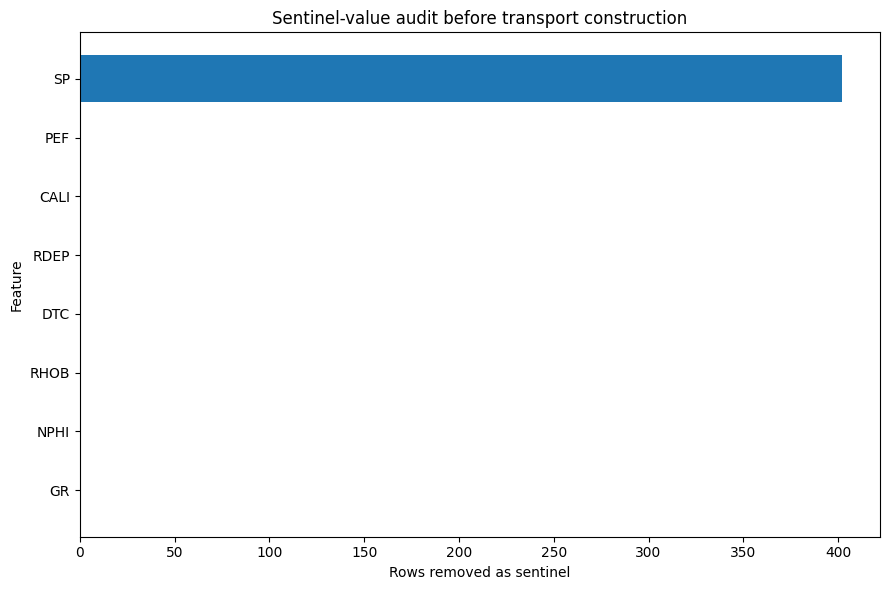

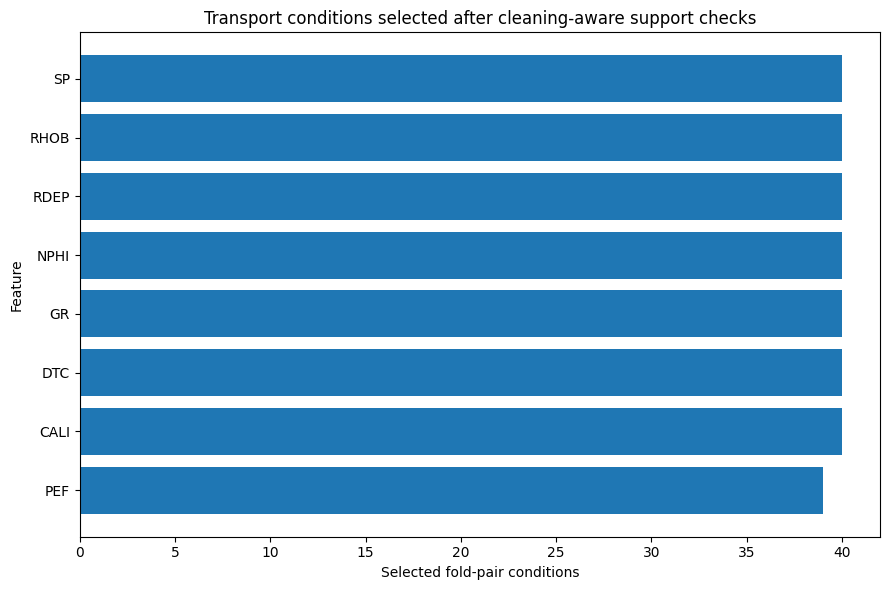



In [13]:
def save_current_figure(
    filename,
):
    plt.tight_layout()
    plt.savefig(
        PLOT_DIR
        / filename,
        dpi=220,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


# Plot 01 — Sentinel و cleaning audit
plot_df = (
    cleaning_audit
    .sort_values(
        "sentinel_rows",
        ascending=True,
    )
)

plt.figure(
    figsize=(9, 6)
)

plt.barh(
    plot_df[
        "feature"
    ],
    plot_df[
        "sentinel_rows"
    ],
)

plt.xlabel(
    "Rows removed as sentinel"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Sentinel-value audit before transport construction"
)

save_current_figure(
    "01_sentinel_value_audit.png"
)


# Plot 02 — تعداد Conditionهای انتخاب‌شده
selected_count_df = (
    condition_registry.loc[
        condition_registry[
            "selected_for_bank"
        ]
        == True
    ]
    .groupby(
        "feature"
    )
    .size()
    .reset_index(
        name="selected_conditions"
    )
    .sort_values(
        "selected_conditions",
        ascending=True,
    )
)

plt.figure(
    figsize=(9, 6)
)

plt.barh(
    selected_count_df[
        "feature"
    ],
    selected_count_df[
        "selected_conditions"
    ],
)

plt.xlabel(
    "Selected fold-pair conditions"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Transport conditions selected after cleaning-aware support checks"
)

save_current_figure(
    "02_selected_condition_count_by_feature.png"
)


# Plot 03 — Eligible rows by condition
if not condition_summary_df.empty:
    plot_df = (
        condition_summary_df.assign(
            condition_label=(
                condition_summary_df[
                    "feature"
                ]
                + ": "
                + condition_summary_df[
                    "source_name"
                ]
                + " → "
                + condition_summary_df[
                    "target_name"
                ]
            )
        )
        .sort_values(
            "eligible_rows",
            ascending=True,
        )
    )

    plt.figure(
        figsize=(
            11,
            max(
                6,
                0.35
                * len(
                    plot_df
                ),
            ),
        )
    )

    plt.barh(
        plot_df[
            "condition_label"
        ],
        plot_df[
            "eligible_rows"
        ],
    )

    plt.xlabel(
        "Eligible outer-validation rows"
    )

    plt.ylabel(
        "Condition"
    )

    plt.title(
        "Eligible source-class rows in the shared transport bank"
    )

    save_current_figure(
        "03_condition_eligible_rows.png"
    )

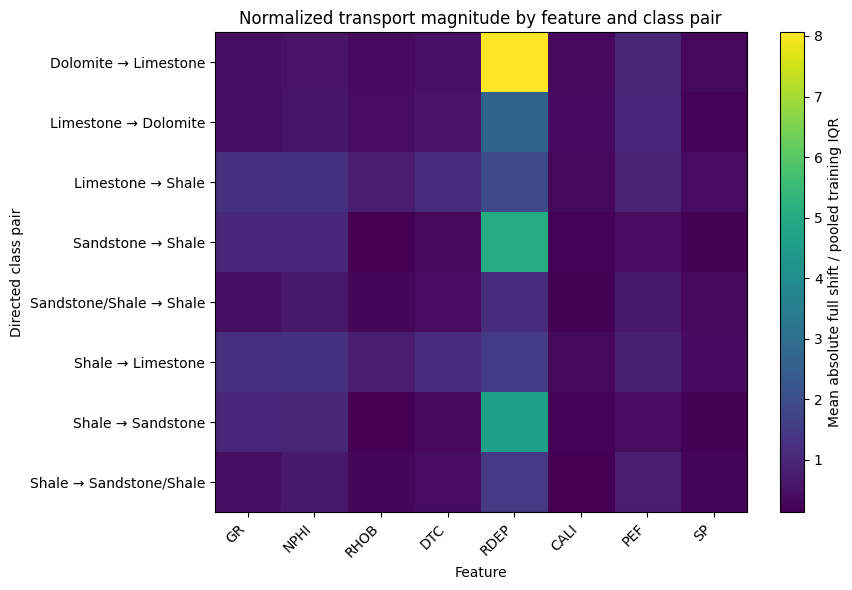



In [14]:
# Plot 04 — Mean normalized full transport shift heatmap-like image
if not condition_summary_df.empty:
    heatmap_source = (
        condition_summary_df.assign(
            pair_label=(
                condition_summary_df[
                    "source_name"
                ]
                + " → "
                + condition_summary_df[
                    "target_name"
                ]
            )
        )
        .pivot_table(
            index="pair_label",
            columns="feature",
            values=(
                "mean_normalized_full_transport_shift"
            ),
            aggfunc="mean",
        )
        .reindex(
            columns=ACTIVE_FEATURES
        )
    )

    matrix = heatmap_source.to_numpy(
        dtype=float
    )

    plt.figure(
        figsize=(
            max(
                9,
                0.9
                * heatmap_source.shape[1],
            ),
            max(
                6,
                0.55
                * heatmap_source.shape[0],
            ),
        )
    )

    image = plt.imshow(
        matrix,
        aspect="auto",
    )

    plt.colorbar(
        image,
        label=(
            "Mean absolute full shift / pooled training IQR"
        ),
    )

    plt.xticks(
        np.arange(
            heatmap_source.shape[1]
        ),
        heatmap_source.columns,
        rotation=45,
        ha="right",
    )

    plt.yticks(
        np.arange(
            heatmap_source.shape[0]
        ),
        heatmap_source.index,
    )

    plt.xlabel(
        "Feature"
    )

    plt.ylabel(
        "Directed class pair"
    )

    plt.title(
        "Normalized transport magnitude by feature and class pair"
    )

    save_current_figure(
        "04_normalized_transport_shift_matrix.png"
    )


# Plot 05 — Mean signed full shift
if not condition_summary_df.empty:
    signed_df = (
        condition_summary_df.assign(
            label=(
                condition_summary_df[
                    "feature"
                ]
                + ": "
                + condition_summary_df[
                    "source_name"
                ]
                + " → "
                + condition_summary_df[
                    "target_name"
                ]
            )
        )
        .sort_values(
            "mean_full_transport_shift",
            ascending=True,
        )
    )

    plt.figure(
        figsize=(
            11,
            max(
                6,
                0.35
                * len(
                    signed_df
                ),
            ),
        )
    )

    plt.barh(
        signed_df[
            "label"
        ],
        signed_df[
            "mean_full_transport_shift"
        ],
    )

    plt.axvline(
        0.0,
        linestyle="--",
    )

    plt.xlabel(
        "Mean target value minus original value"
    )

    plt.ylabel(
        "Condition"
    )

    plt.title(
        "Direction of full class-conditional transport"
    )

    save_current_figure(
        "05_mean_signed_transport_shift.png"
    )

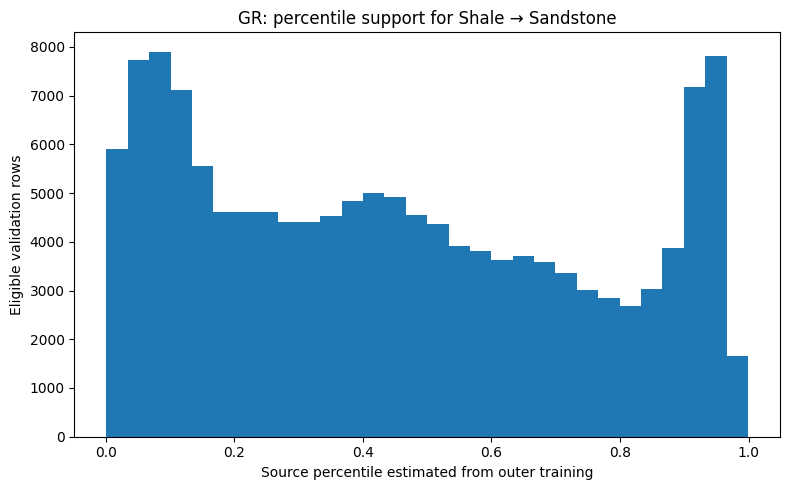

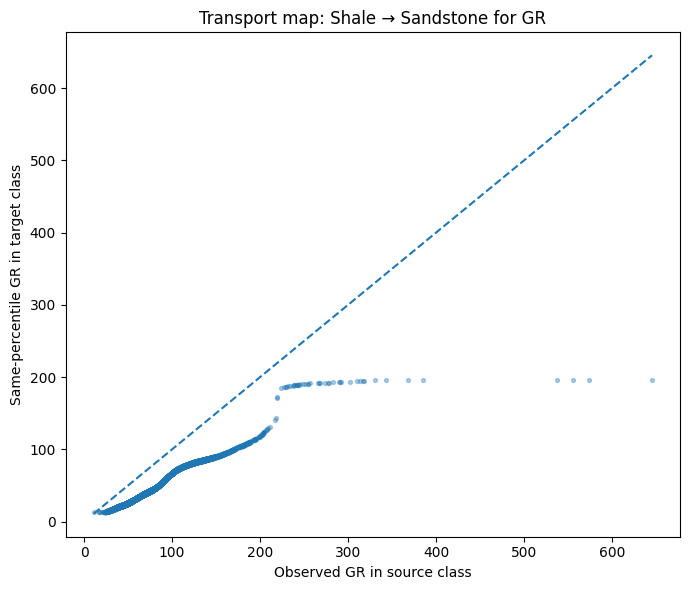

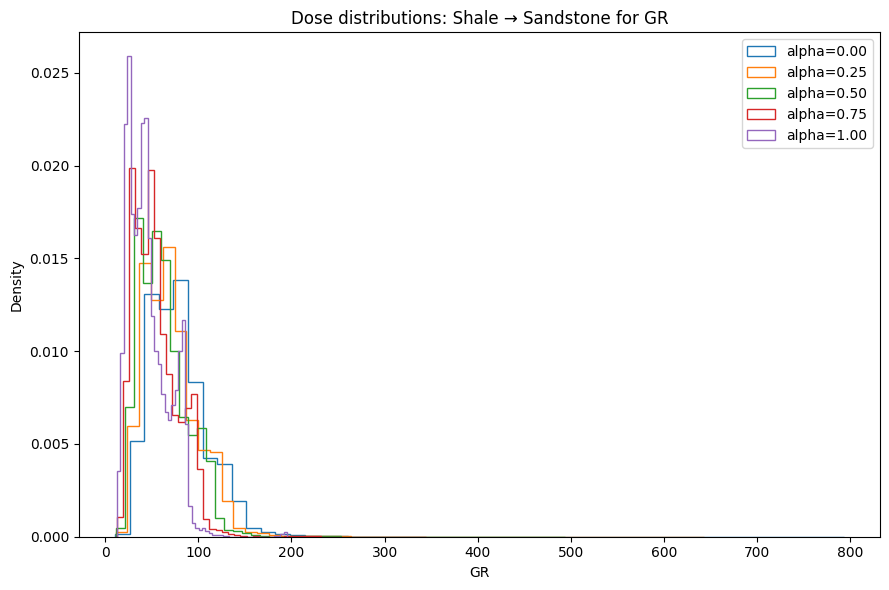

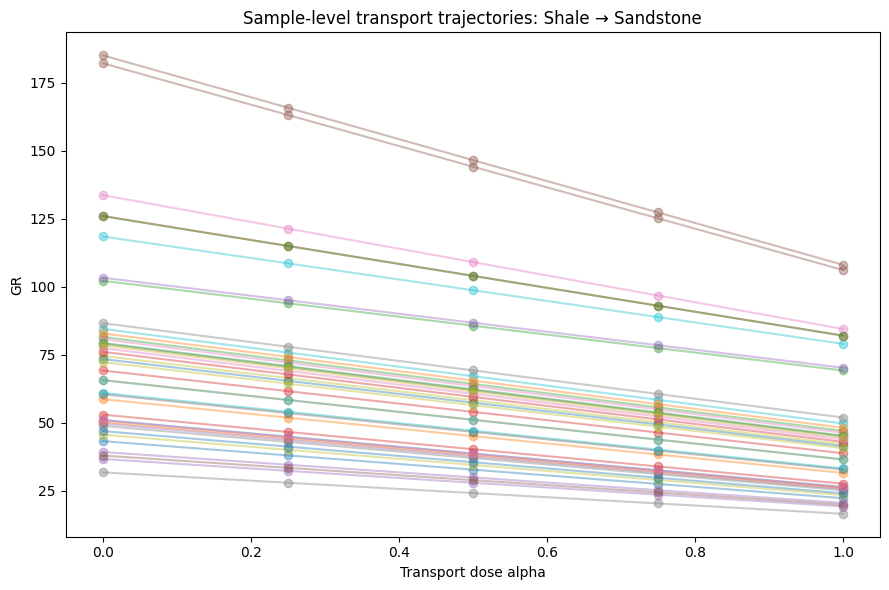

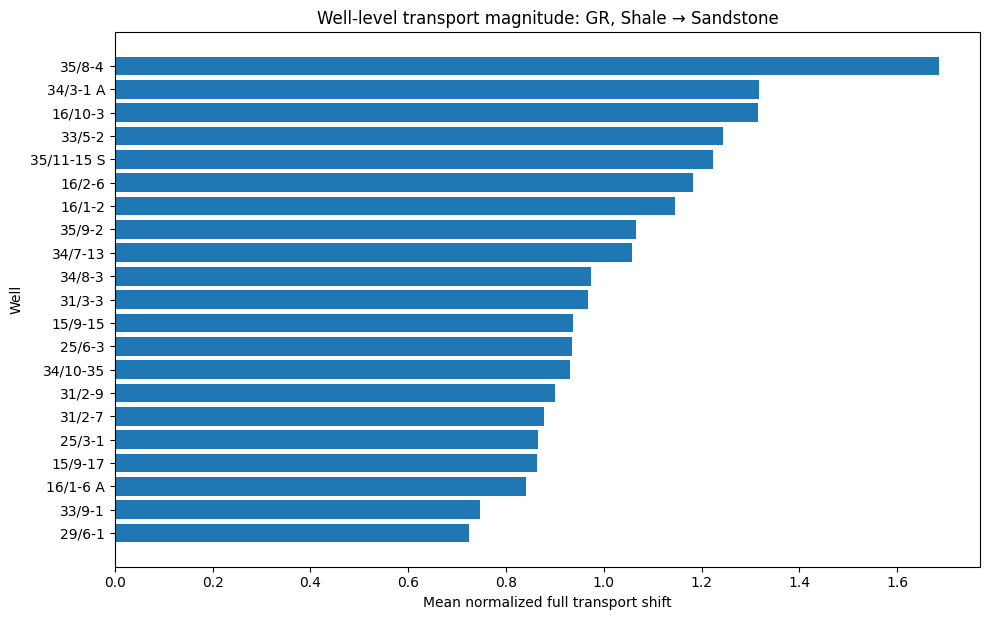

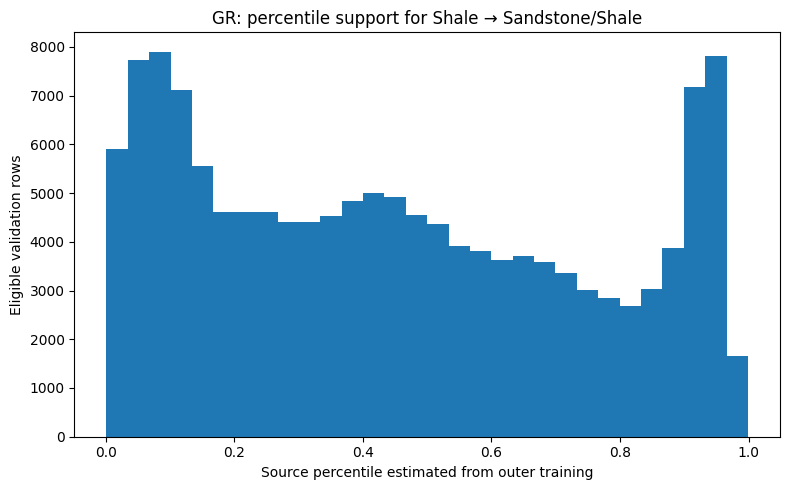

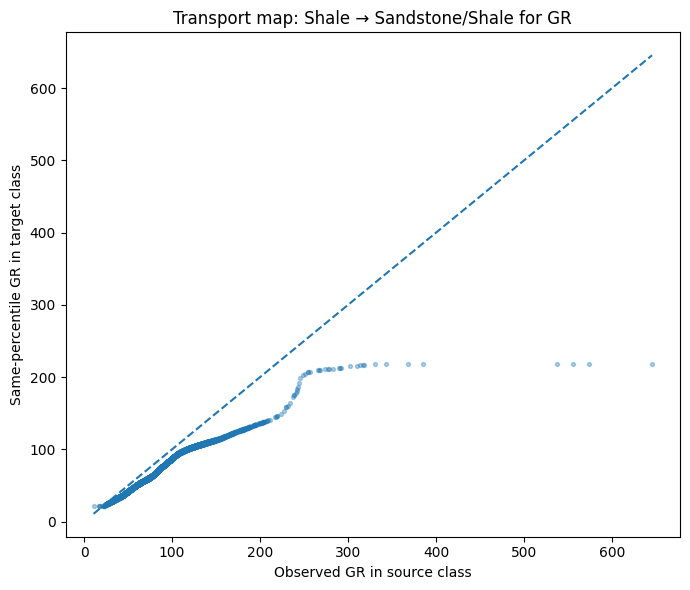

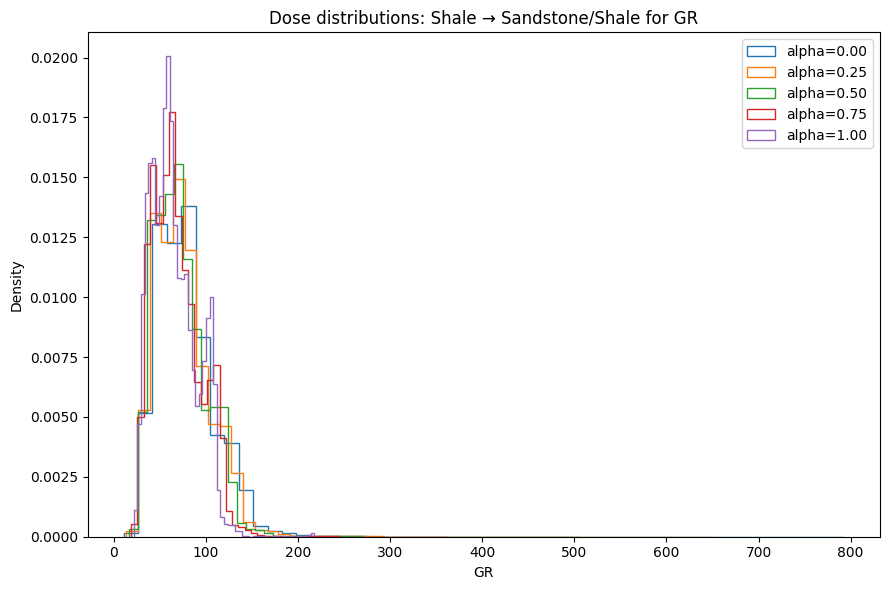

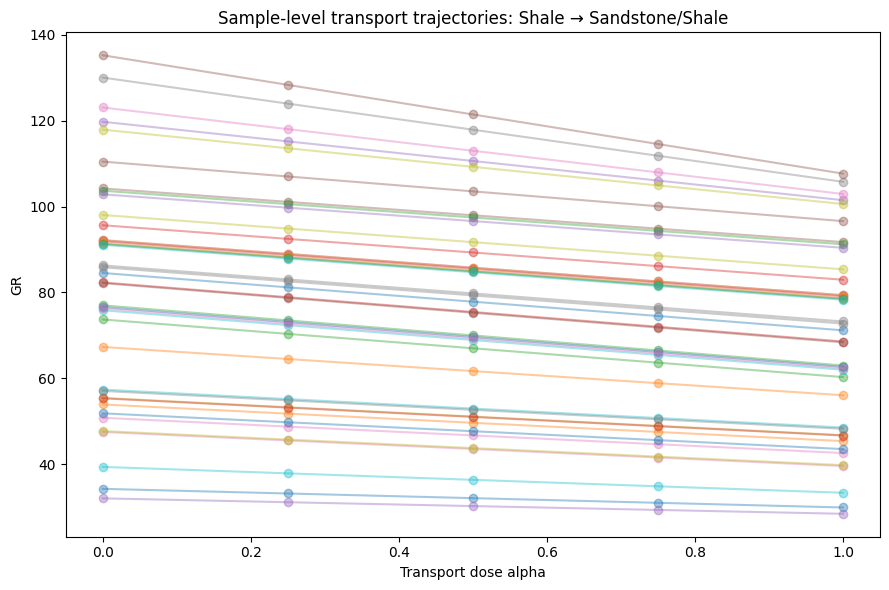

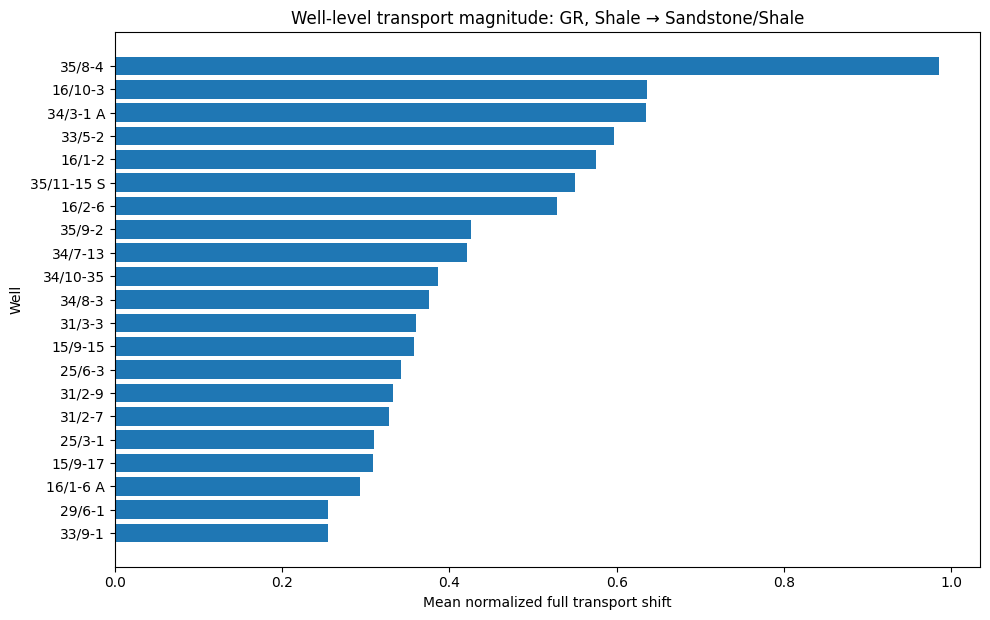

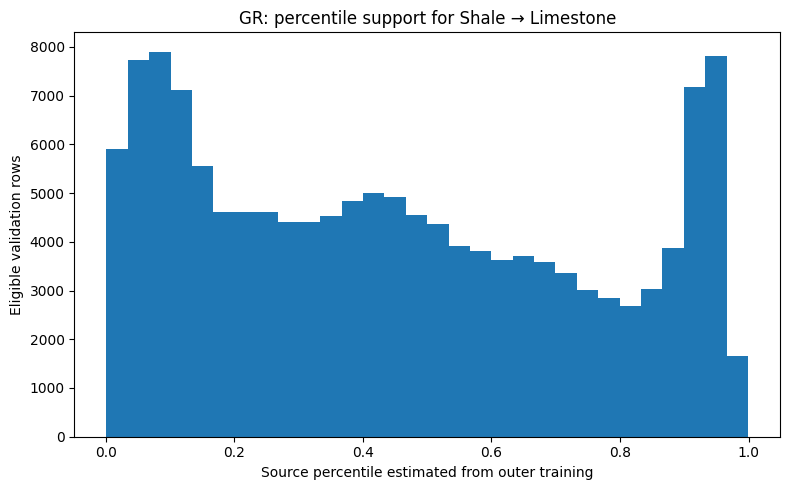

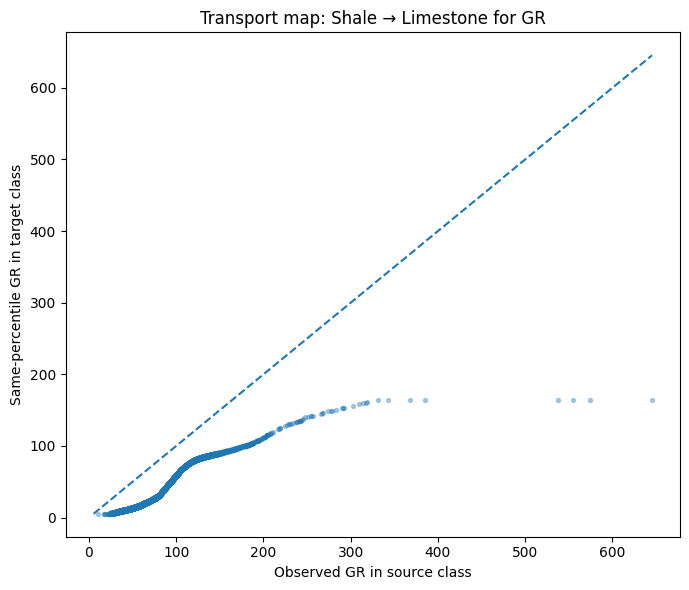

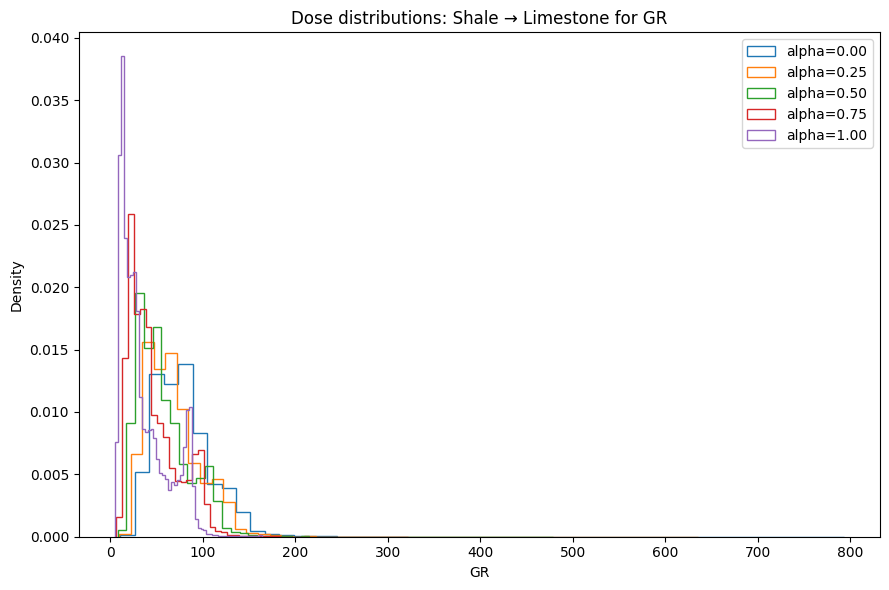

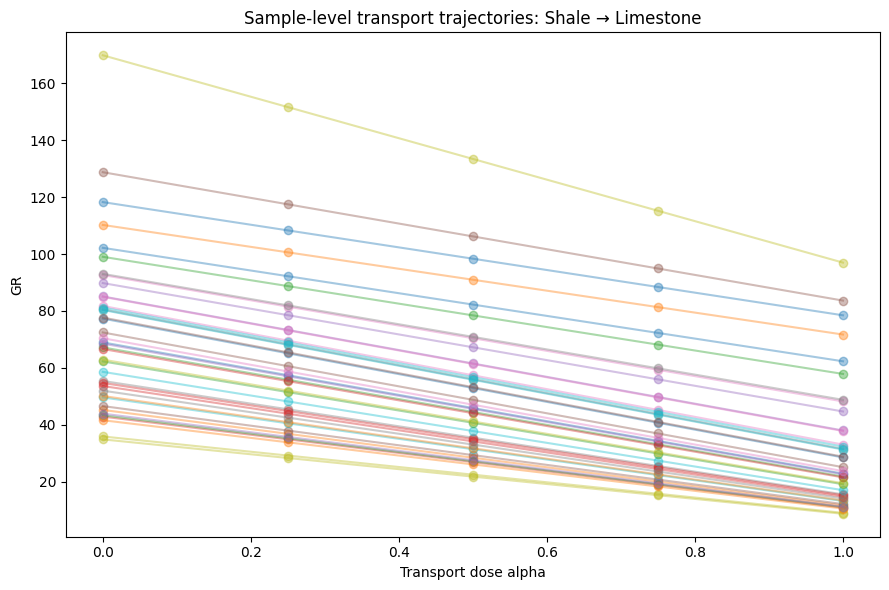

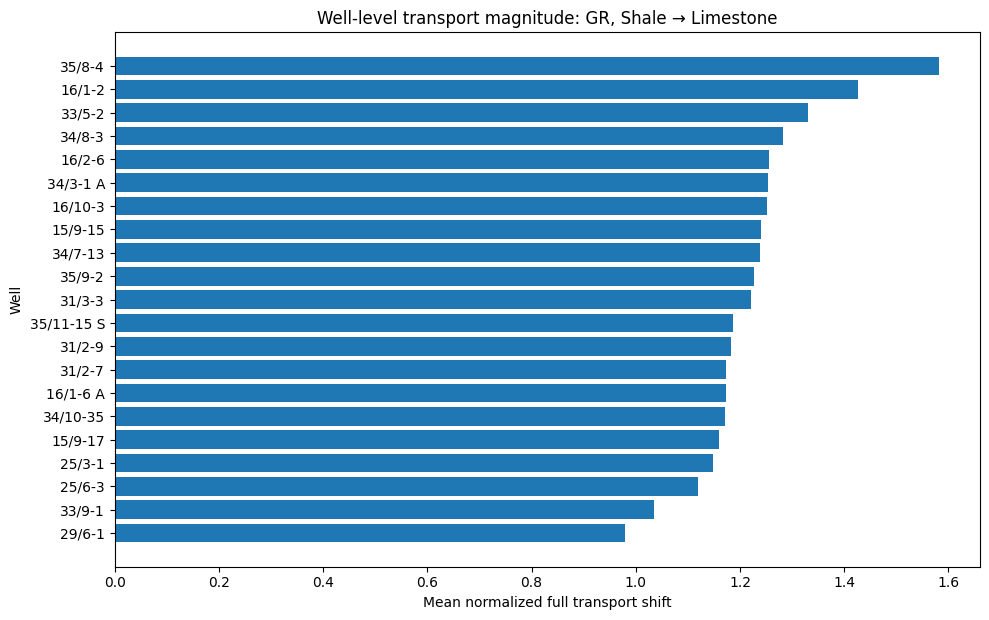

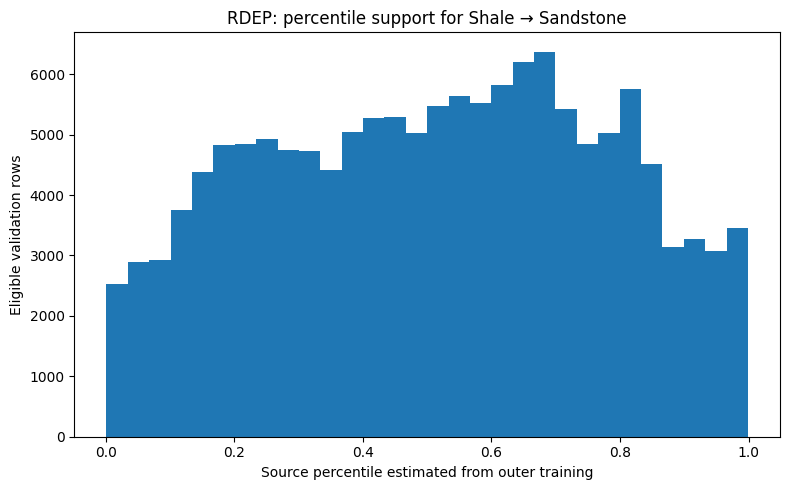

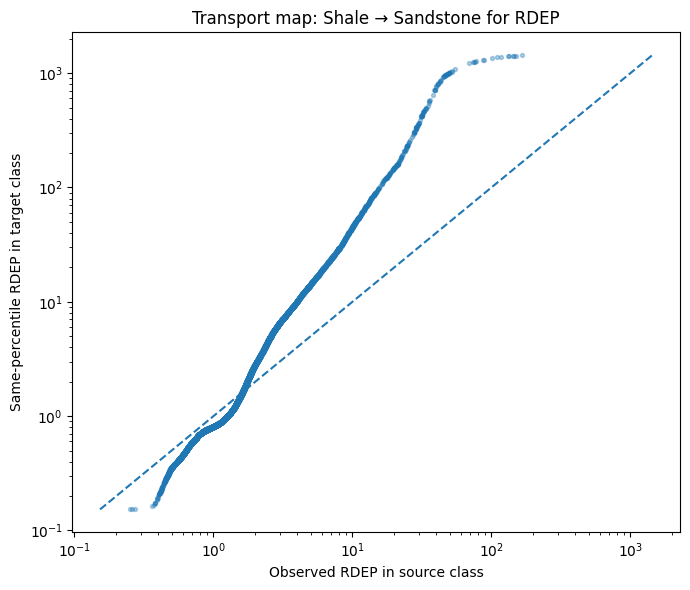

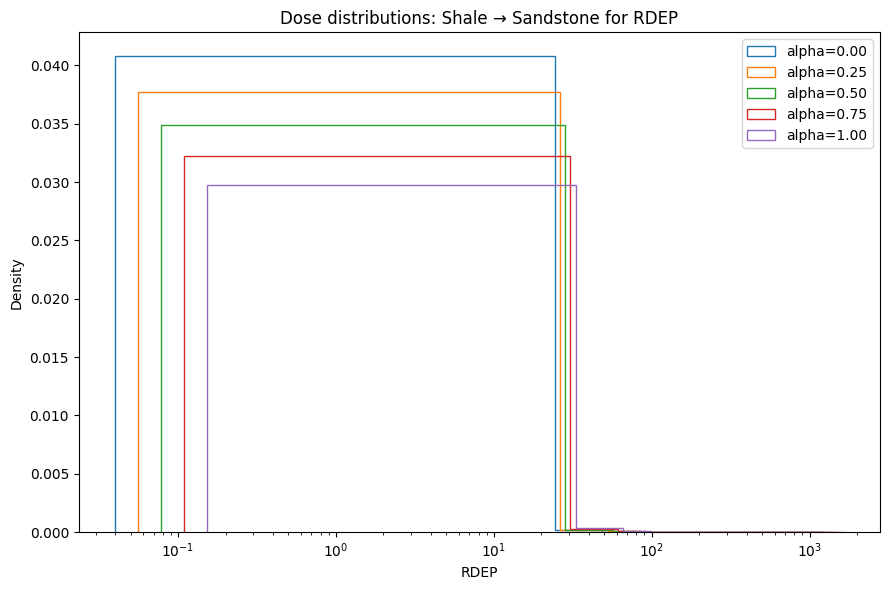

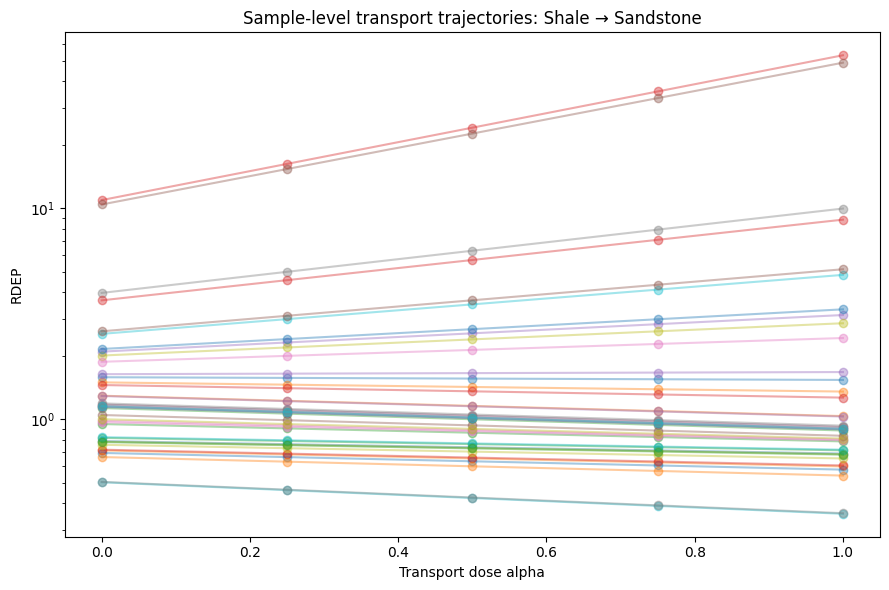

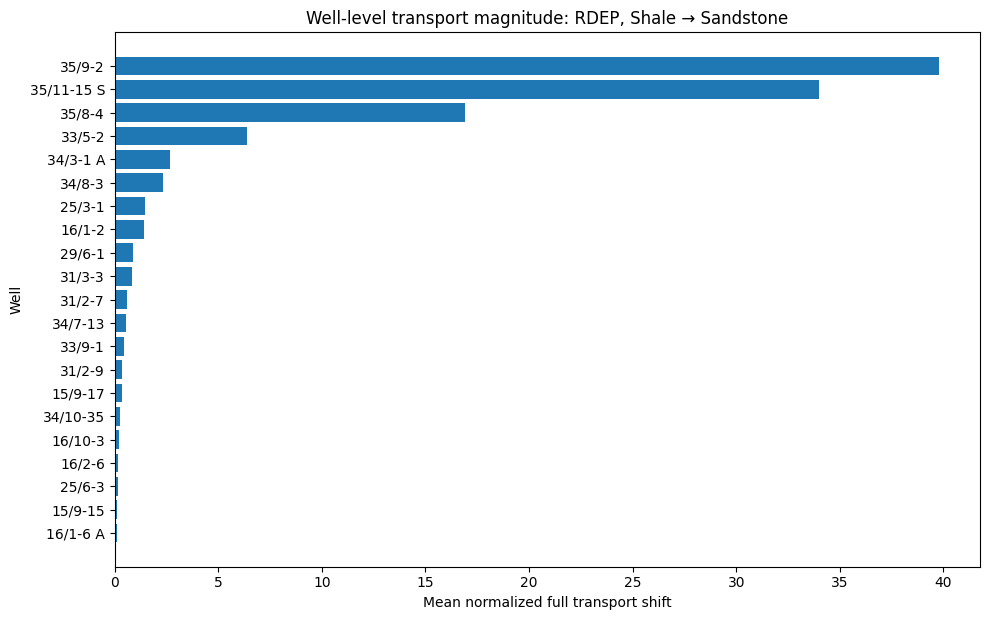

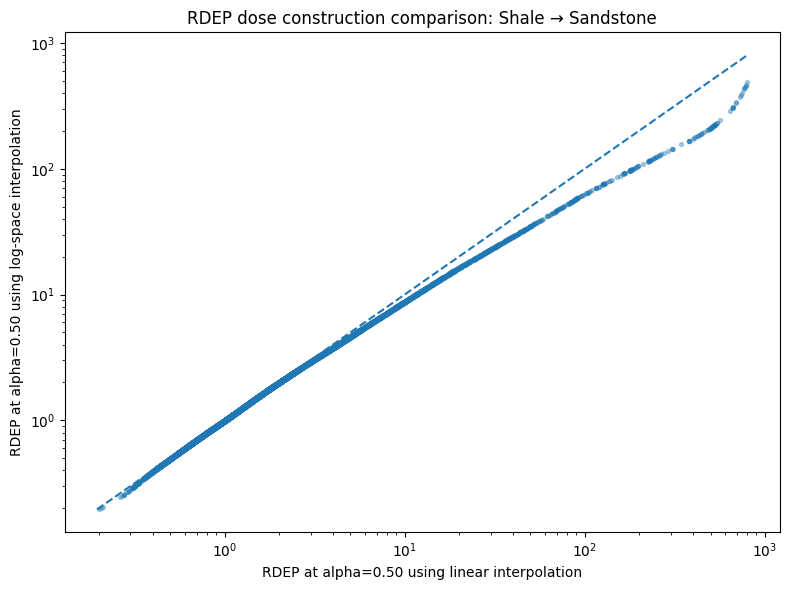

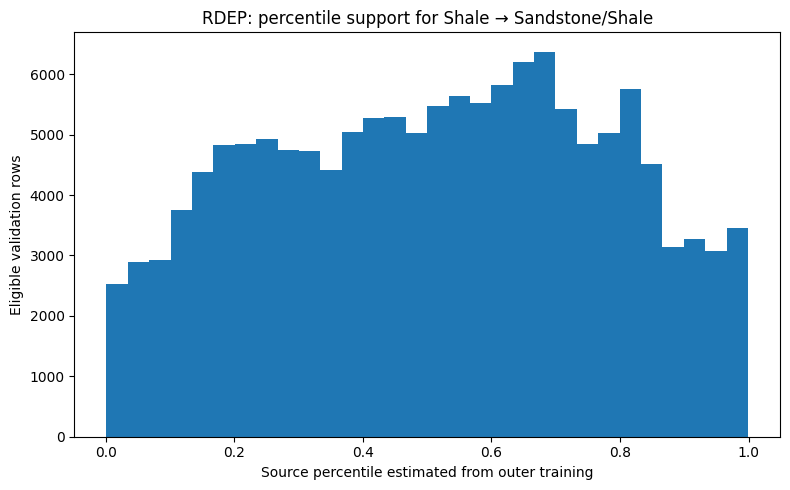

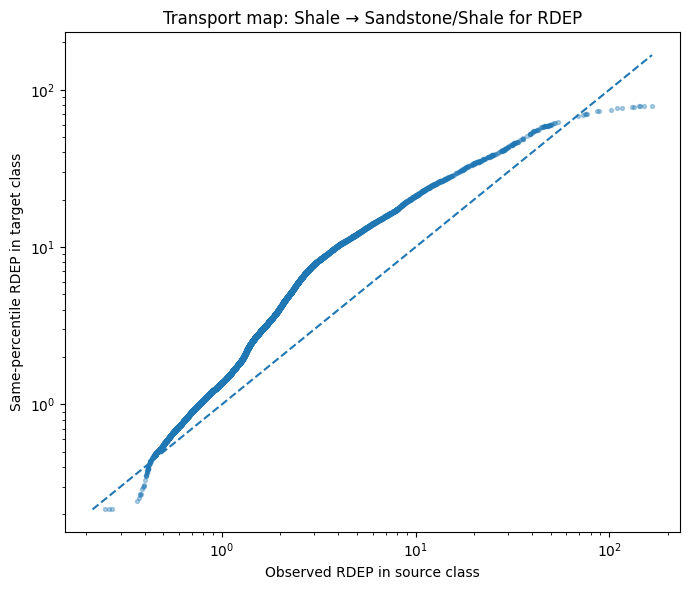

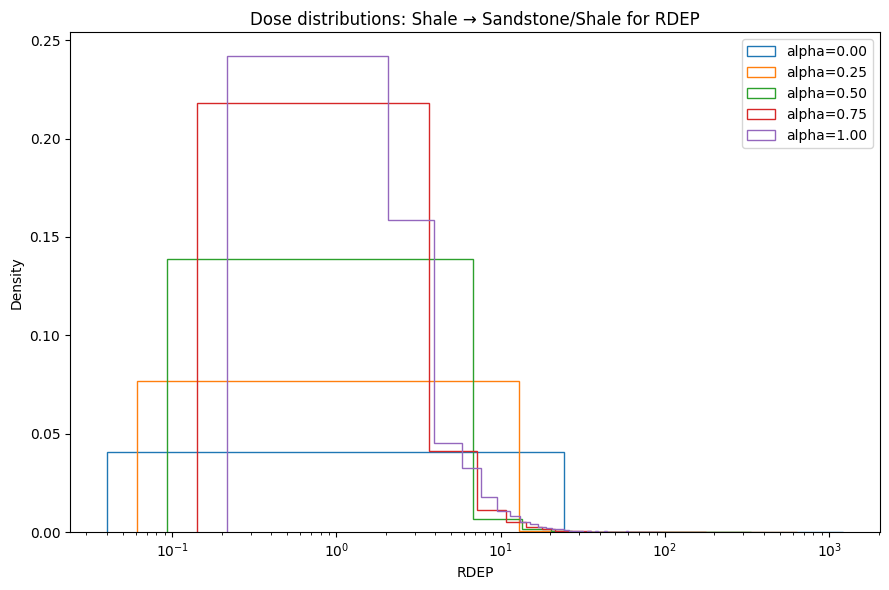

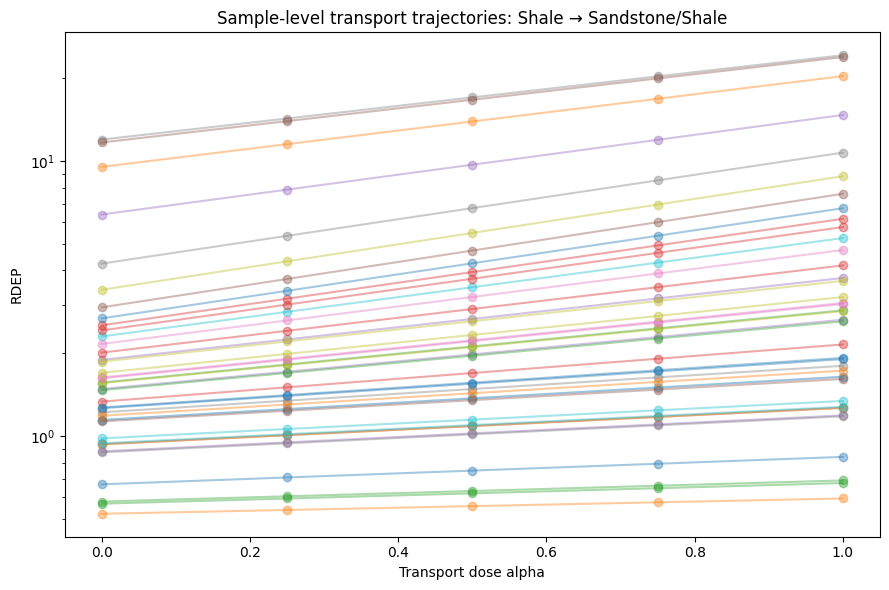

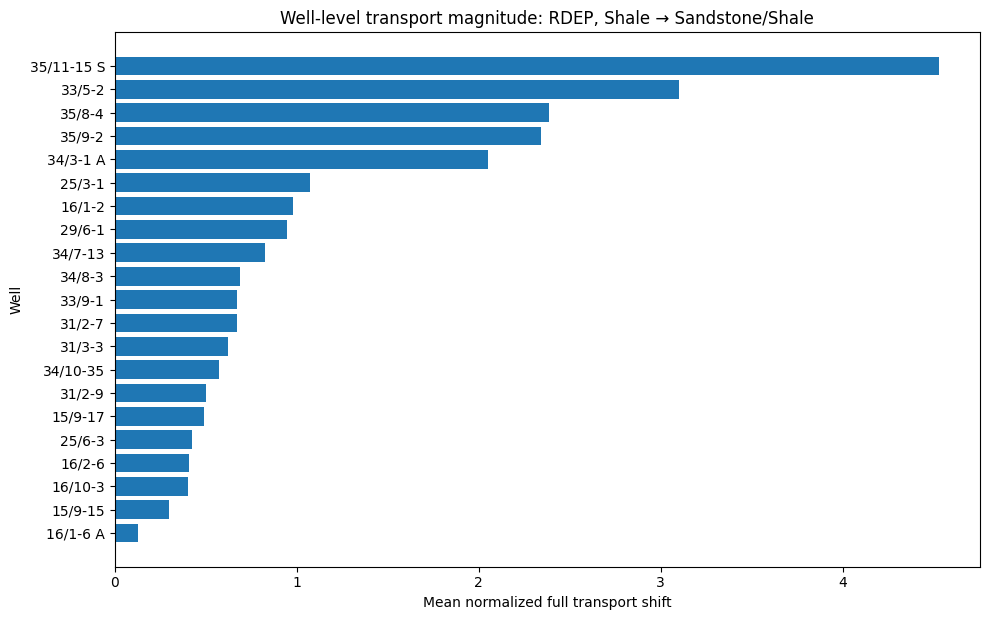

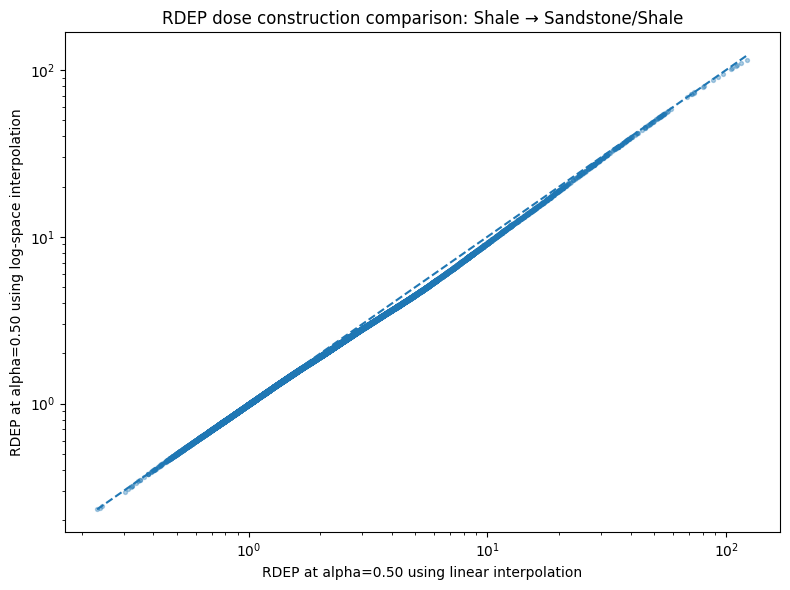

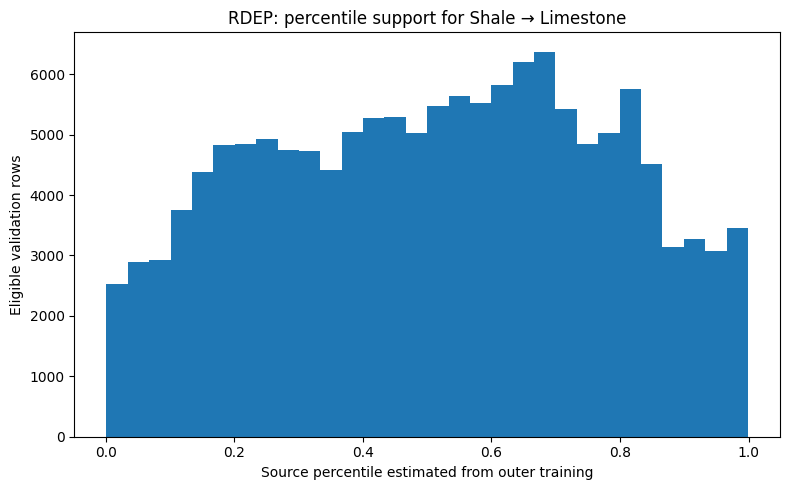

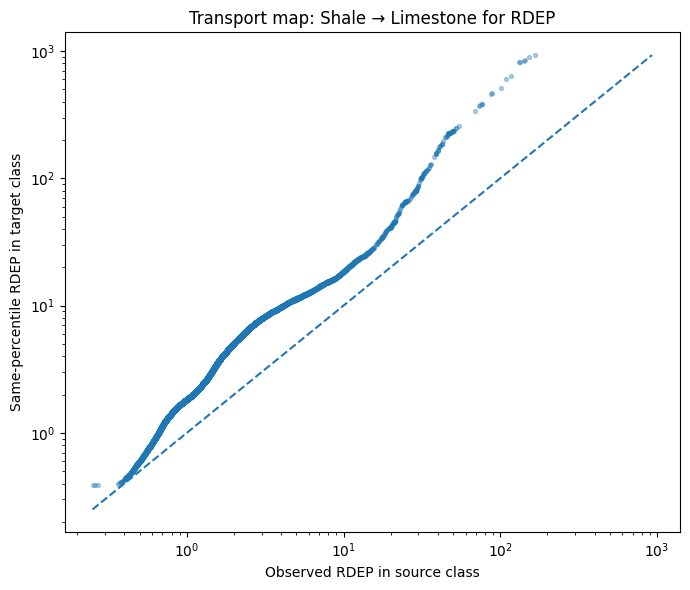

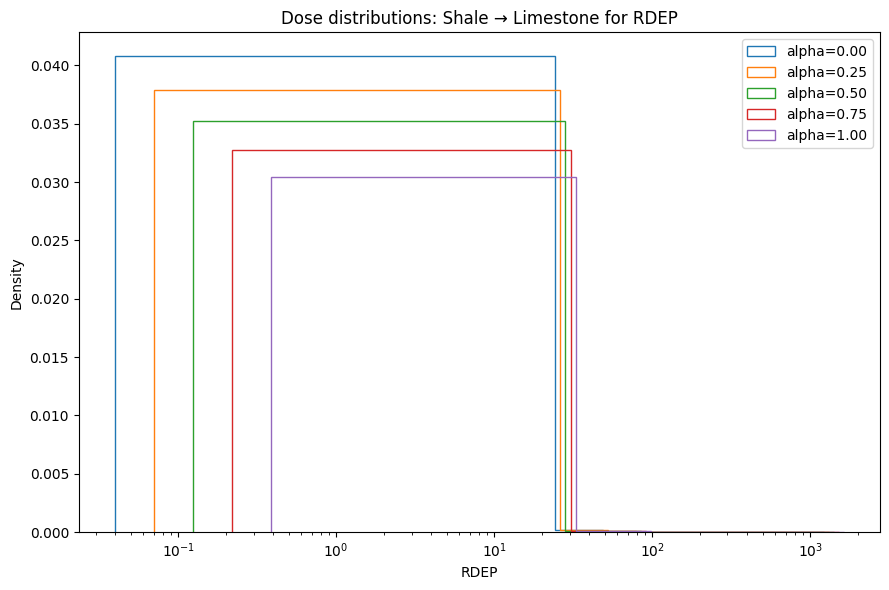

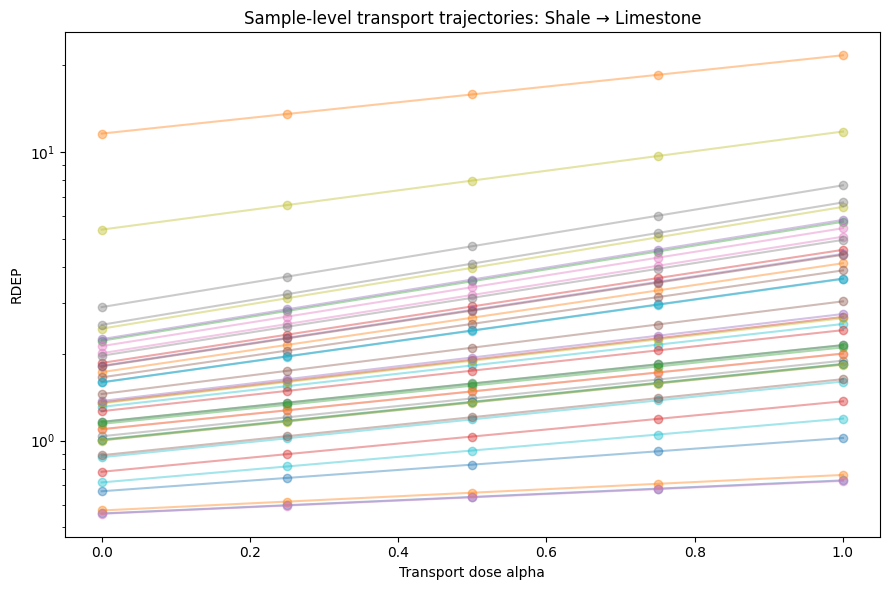

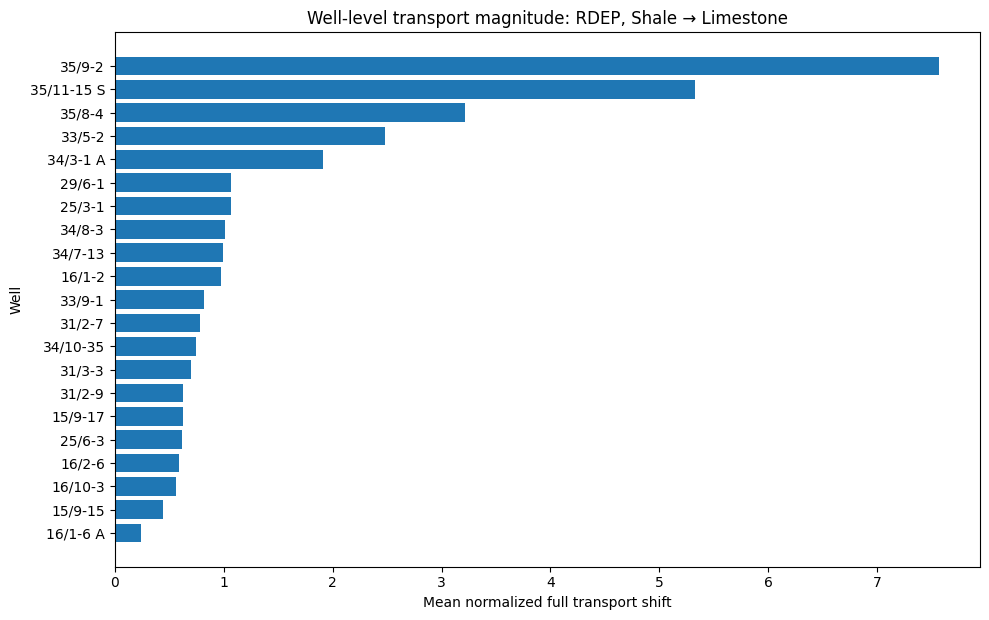

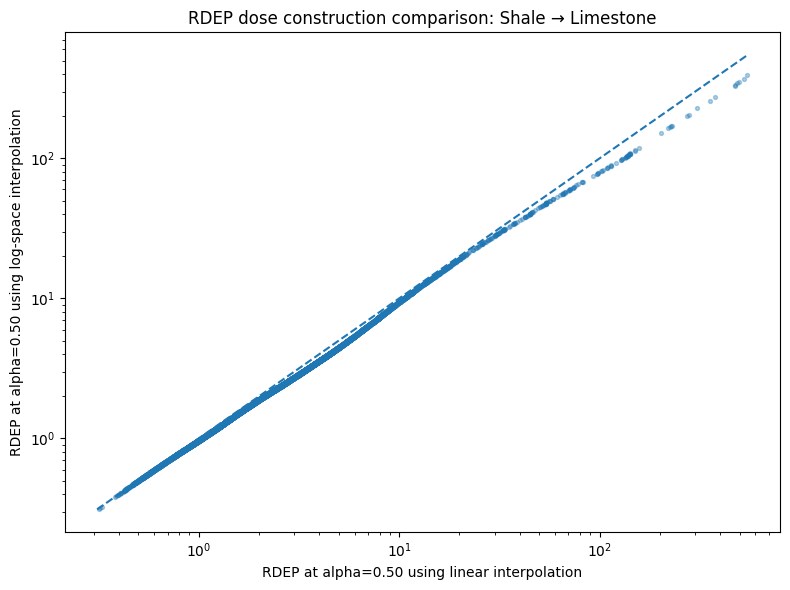

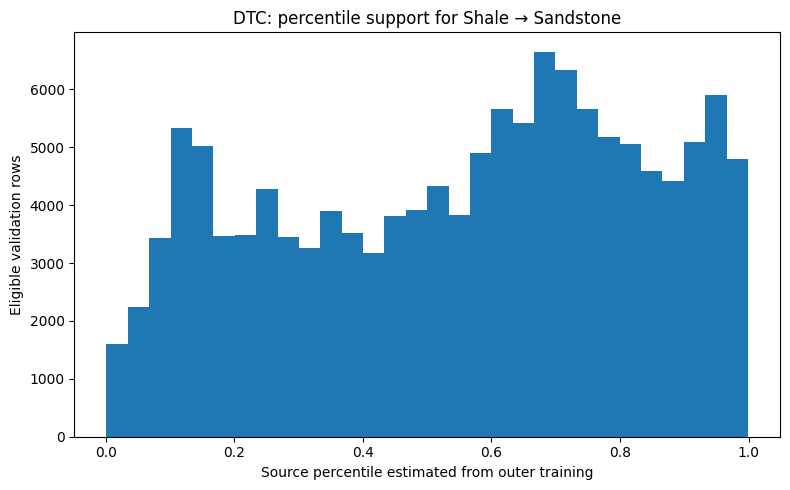

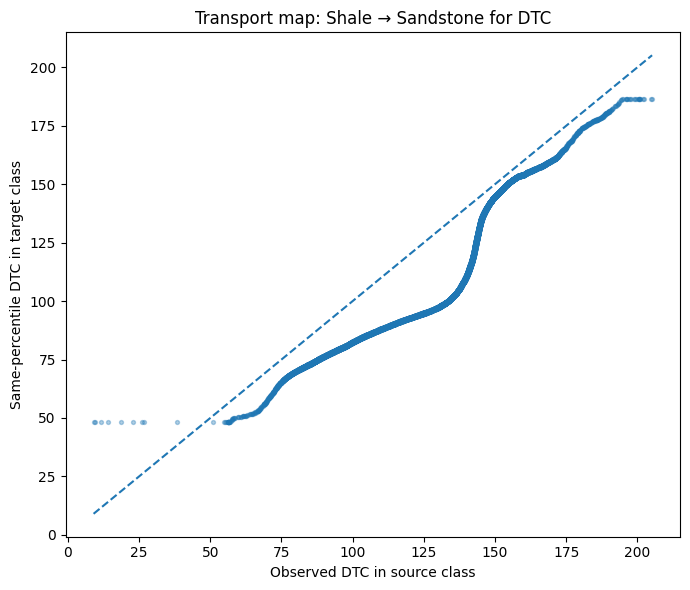

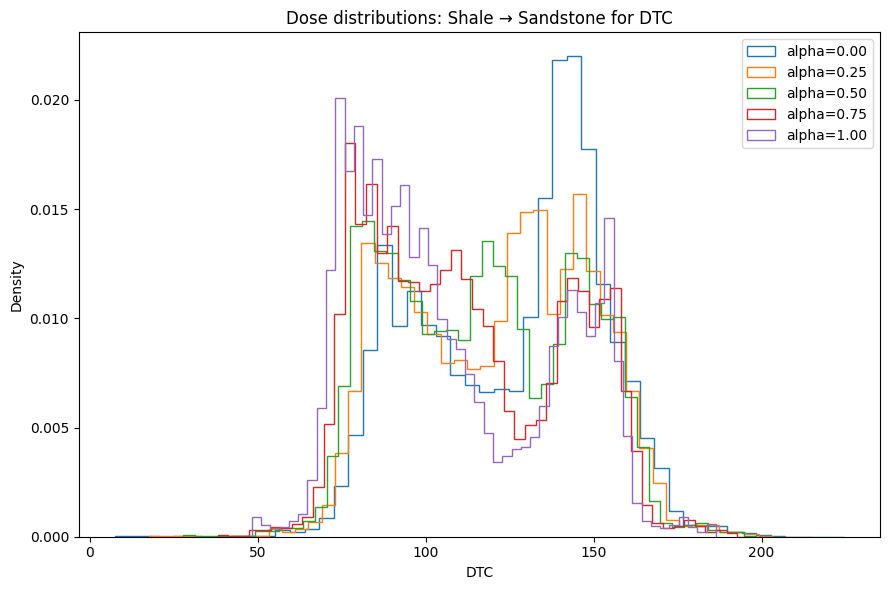

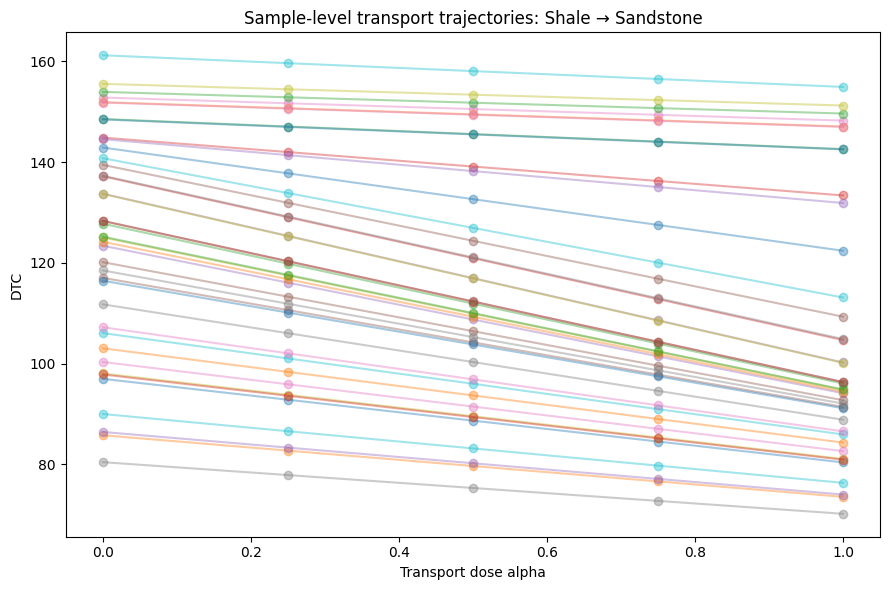

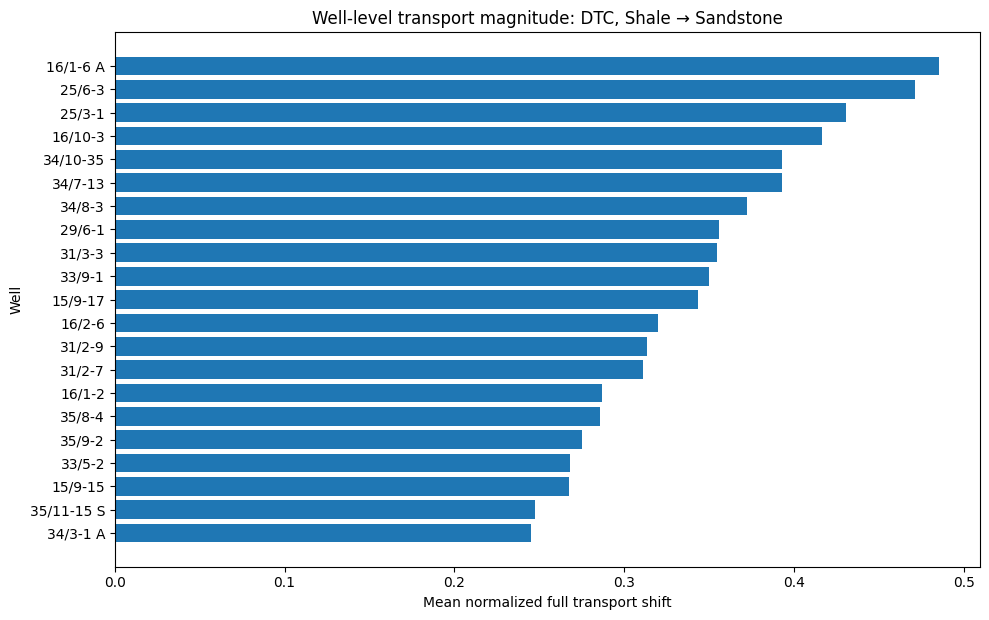

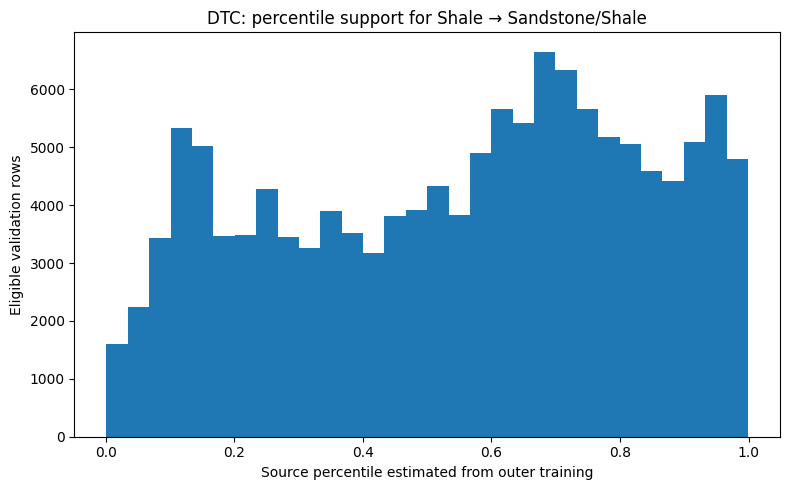

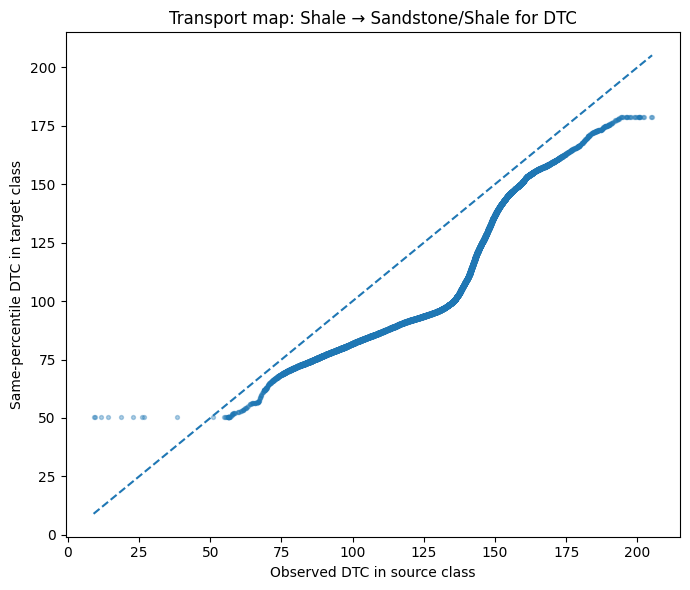

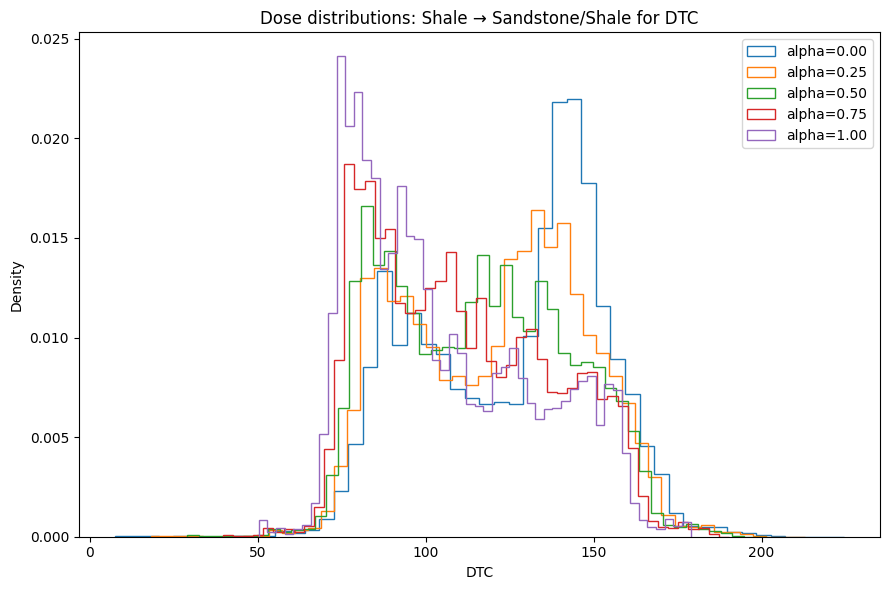

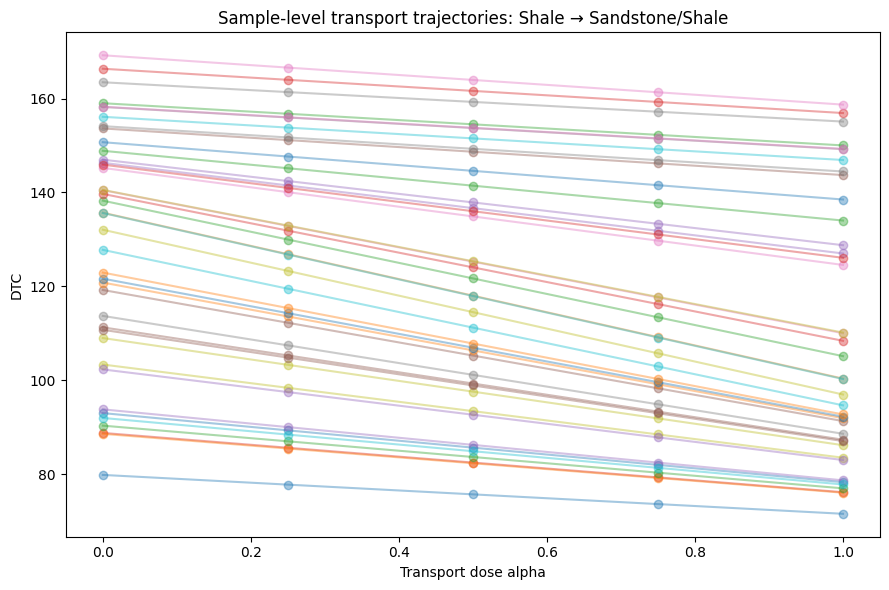

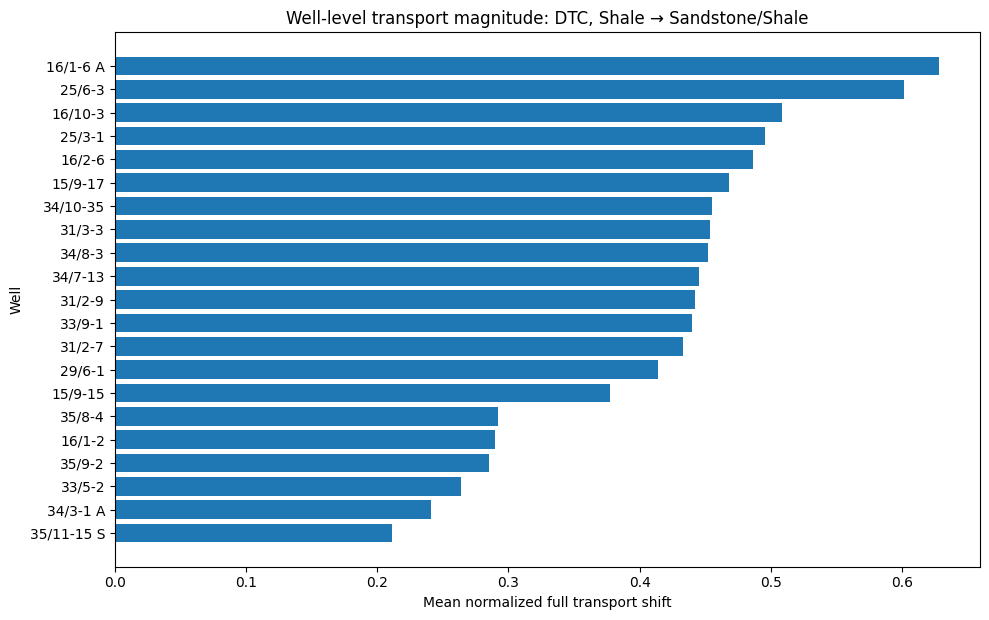

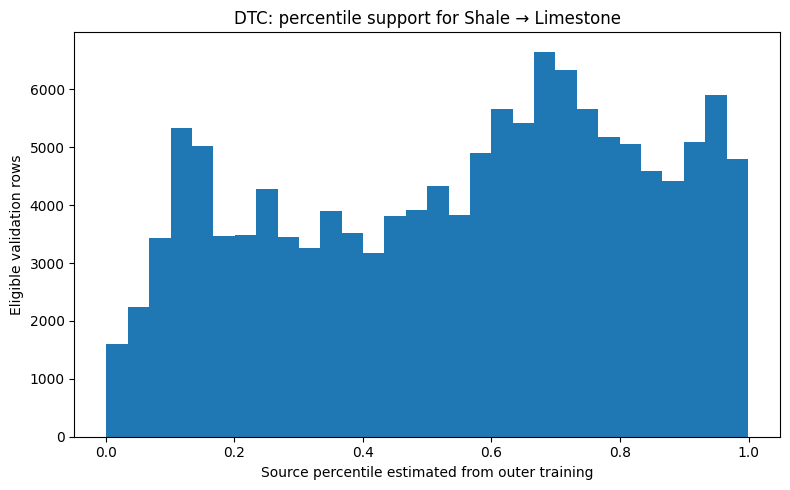

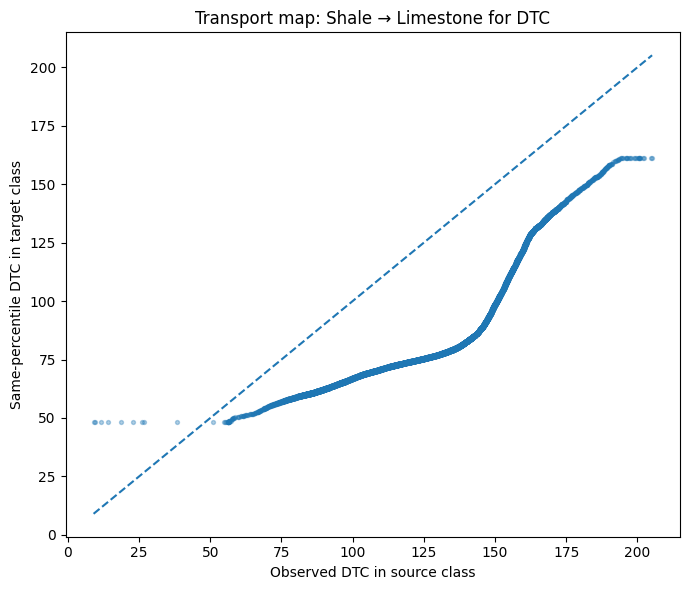

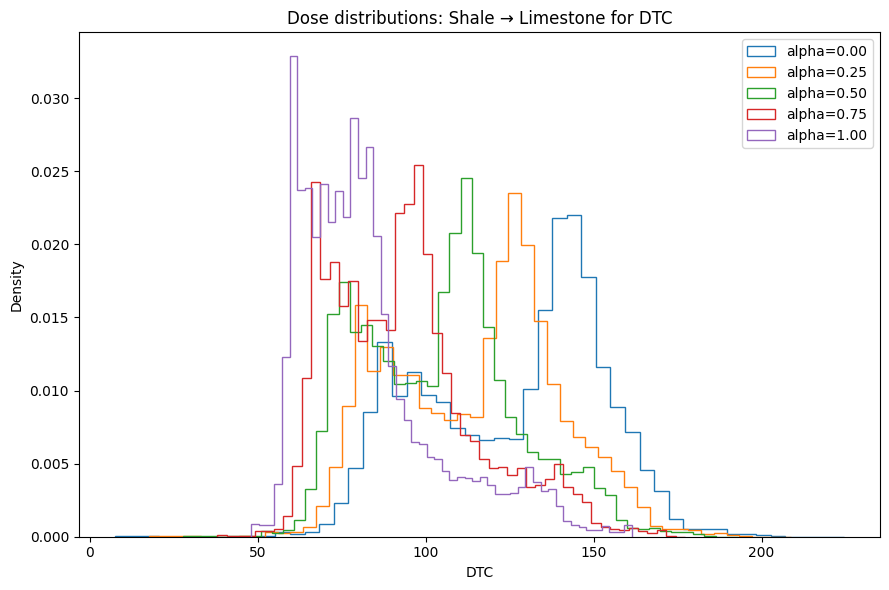

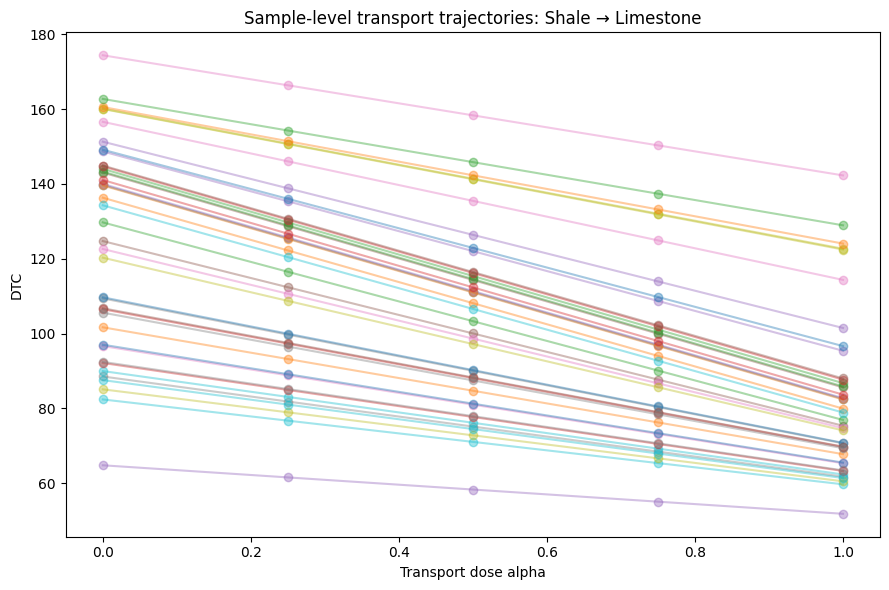

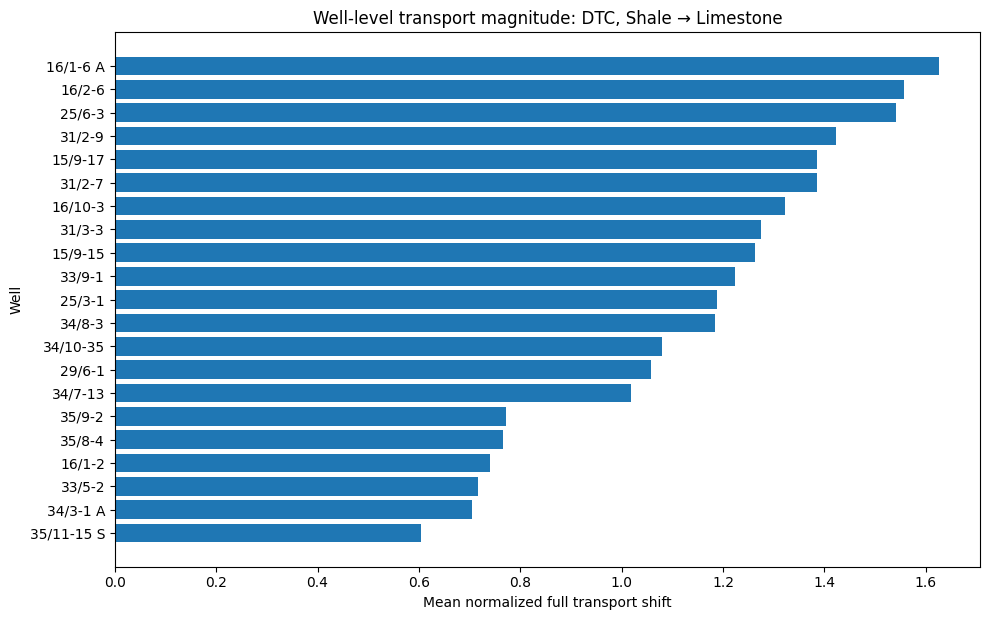

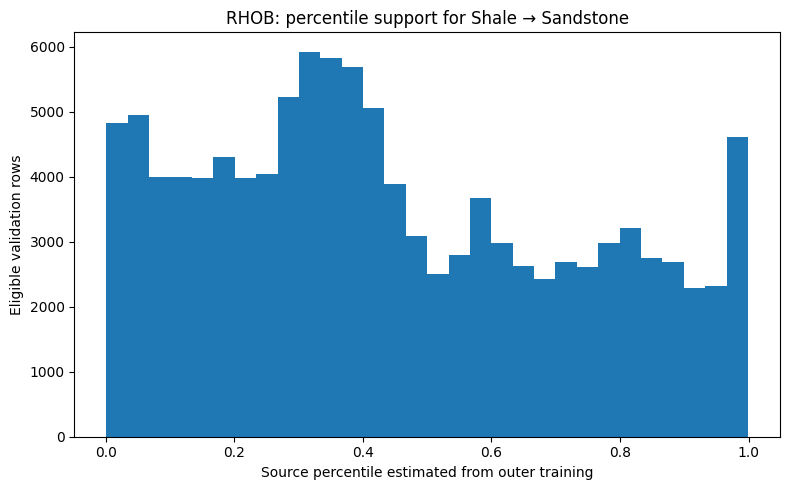

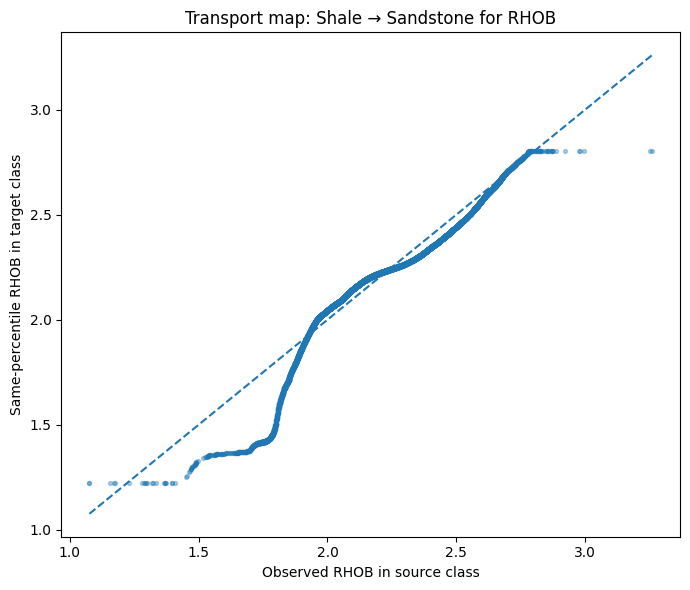

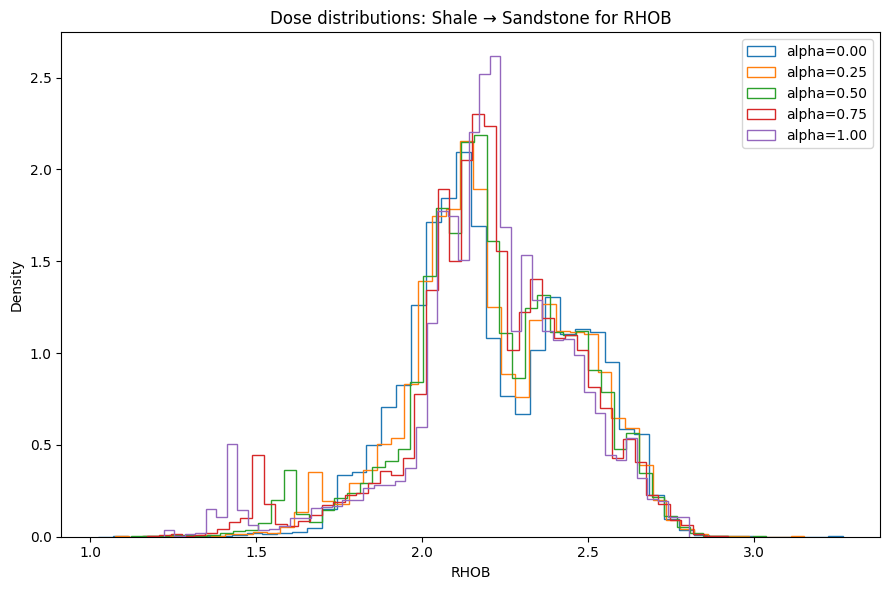

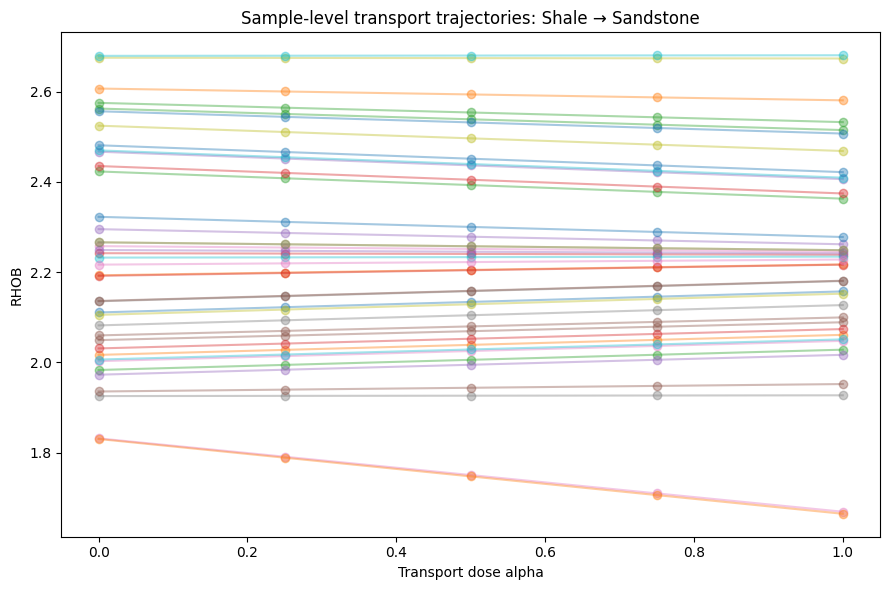

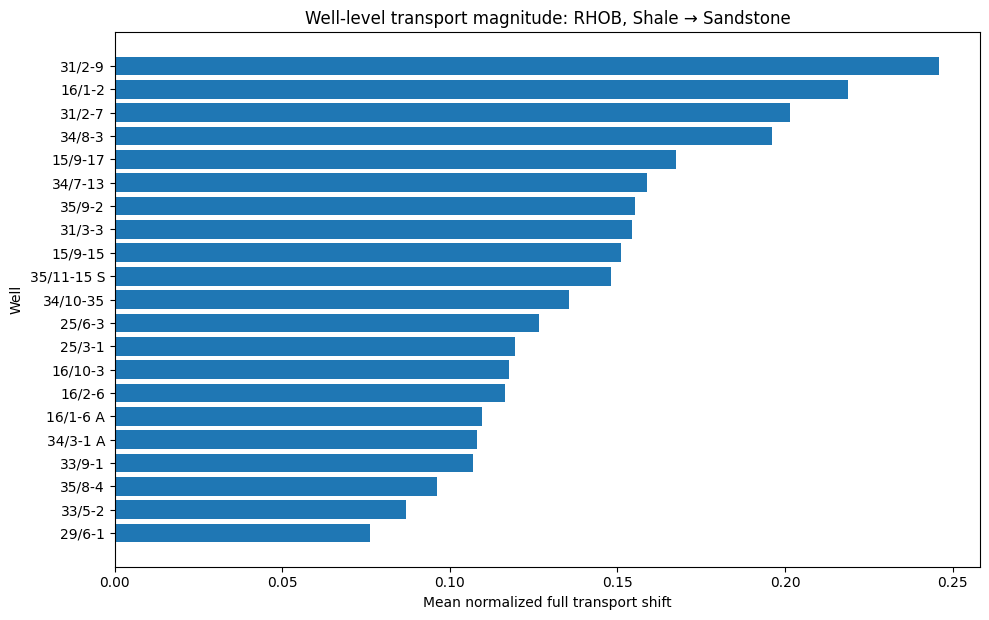

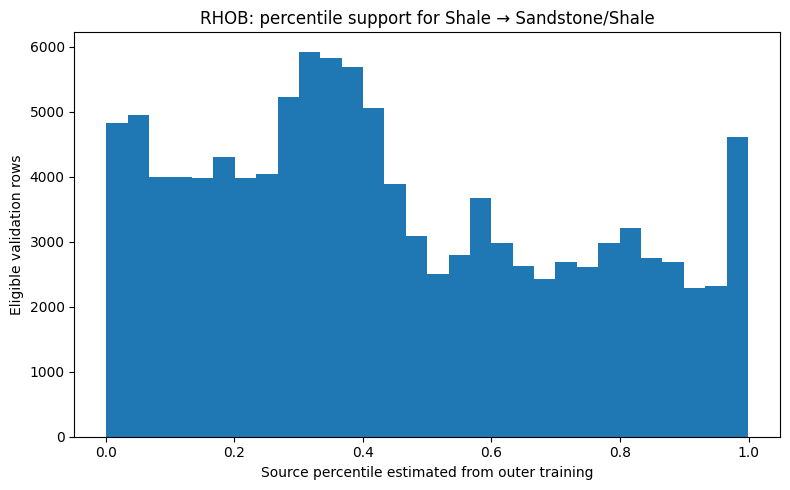

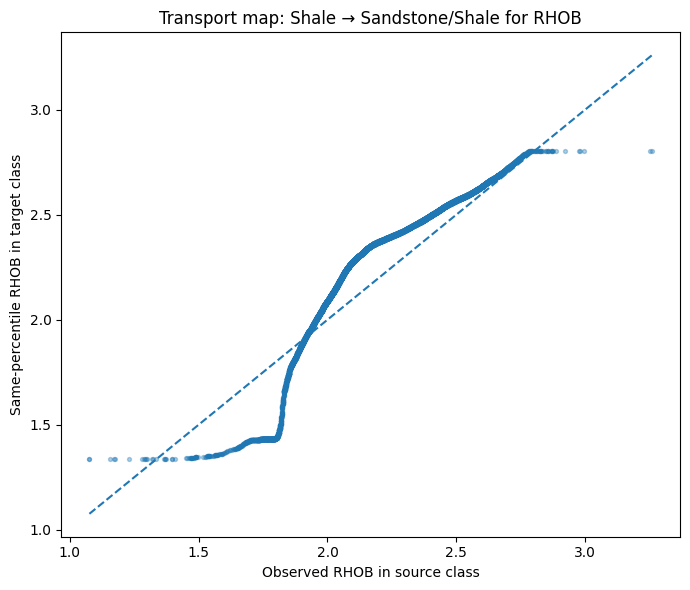

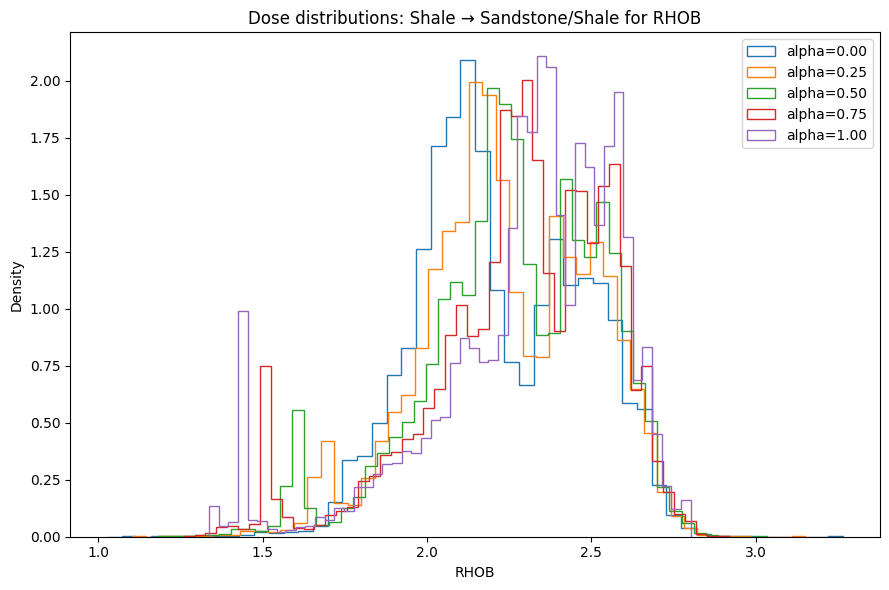

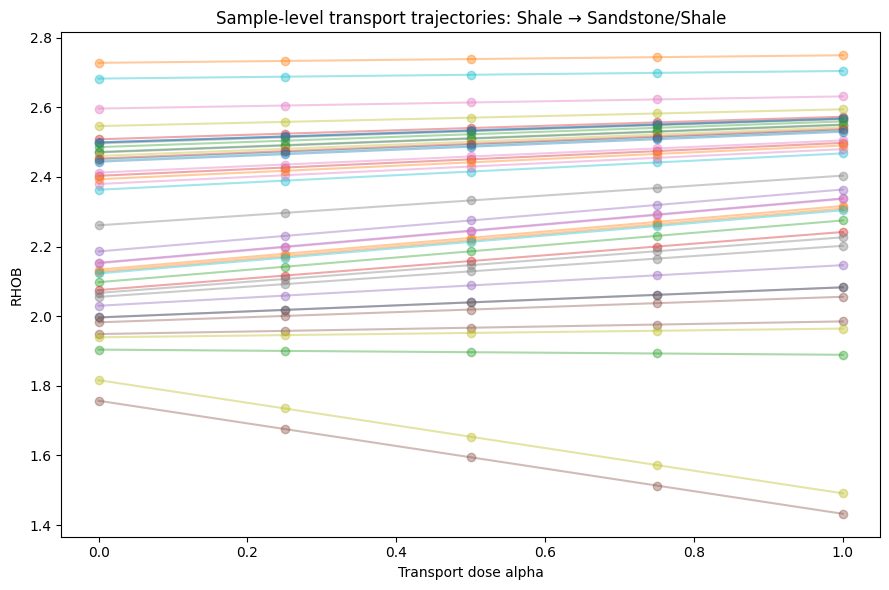

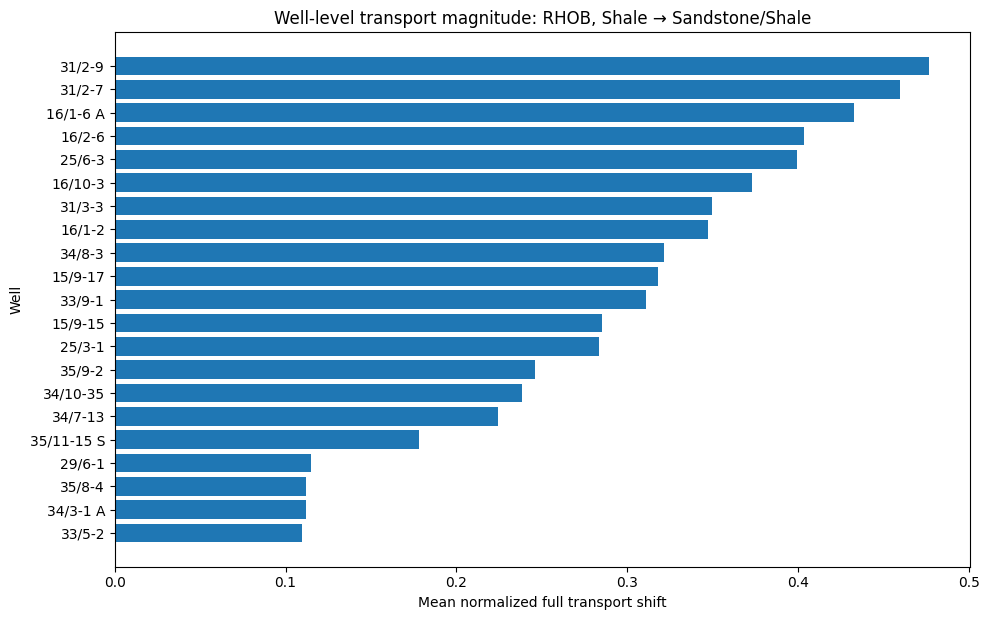

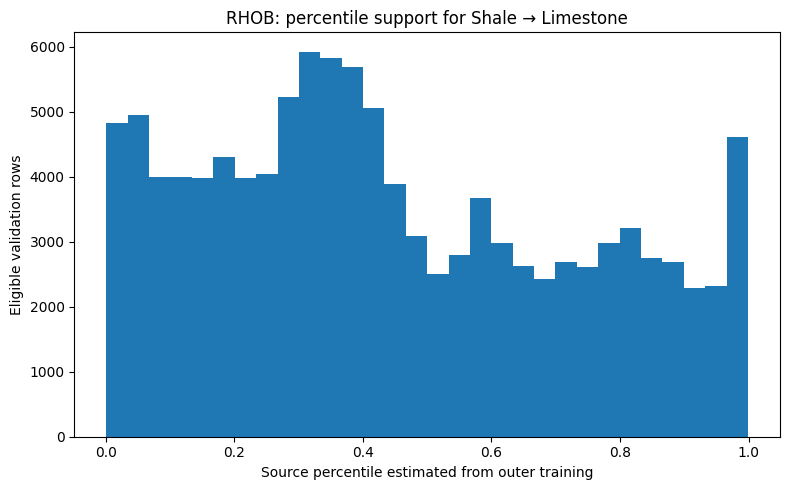

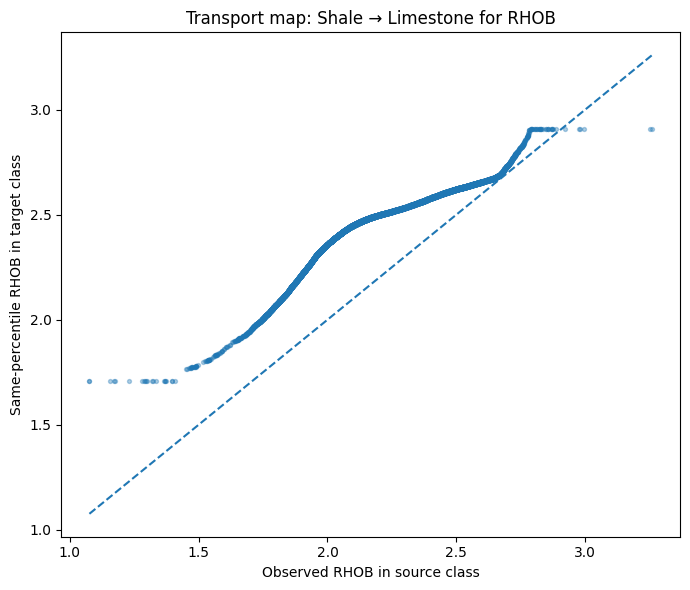

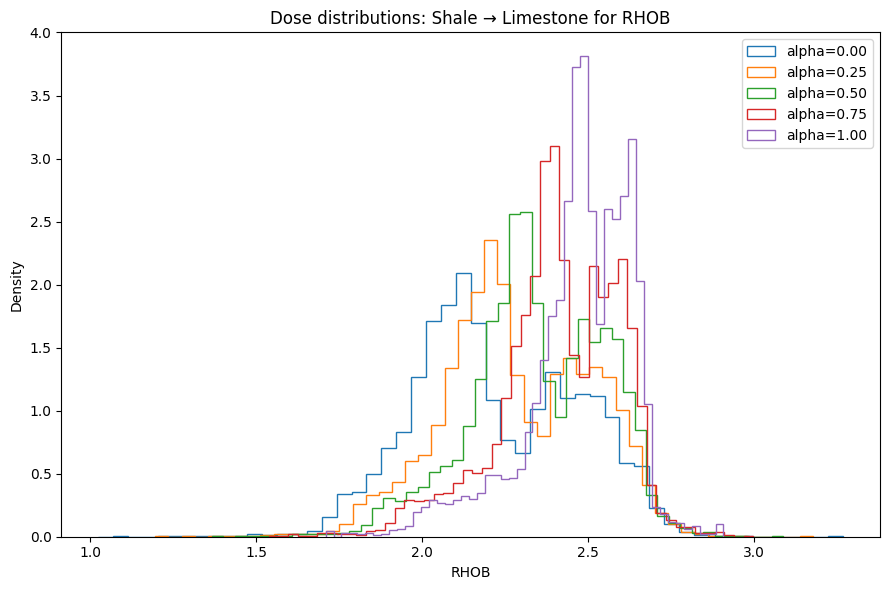

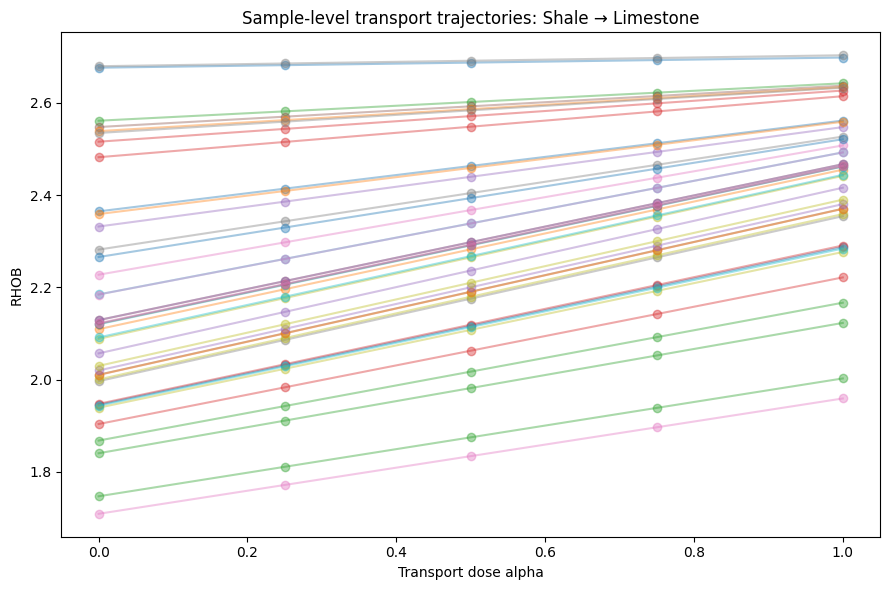

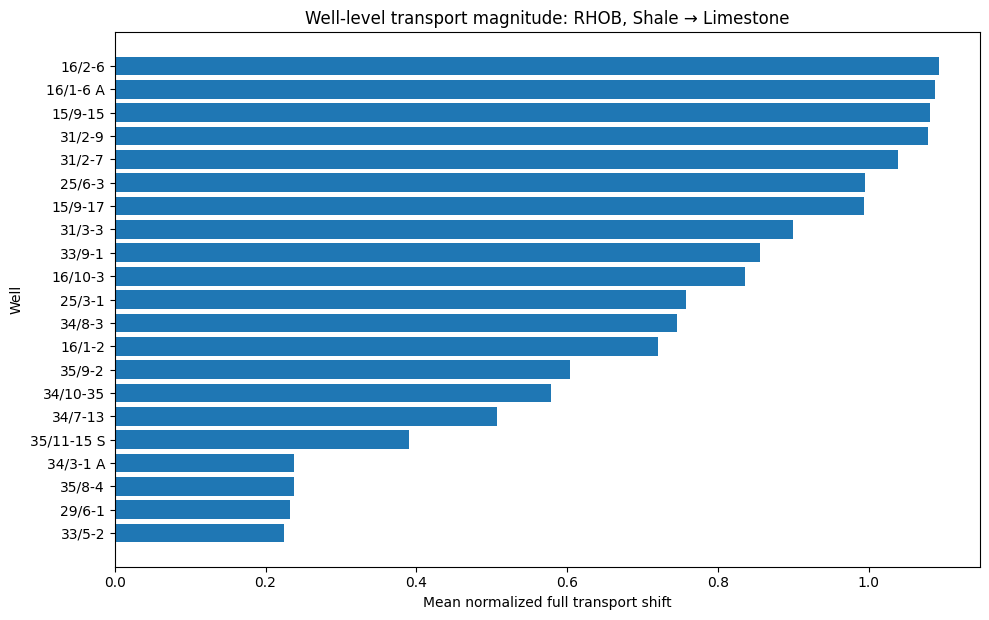

In [15]:
diagnostic_conditions = (
    condition_summary_df
    .sort_values(
        [
            "eligible_wells",
            "eligible_rows",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .head(
        MAX_CONDITION_DIAGNOSTIC_PLOTS
    )
)

random_generator = np.random.default_rng(
    RANDOM_STATE_FOR_PLOTS
)

for _, summary_row in diagnostic_conditions.iterrows():
    condition_id = summary_row[
        "condition_id"
    ]

    bank_path = Path(
        summary_row[
            "bank_path"
        ]
    )

    bank = pd.read_parquet(
        bank_path
    )

    feature = summary_row[
        "feature"
    ]

    source_name = summary_row[
        "source_name"
    ]

    target_name = summary_row[
        "target_name"
    ]

    safe_condition = safe_file_component(
        condition_id
    )

    # Plot A — Source percentile histogram
    plt.figure(
        figsize=(8, 5)
    )

    plt.hist(
        bank[
            "source_percentile"
        ],
        bins=30,
    )

    plt.xlabel(
        "Source percentile estimated from outer training"
    )

    plt.ylabel(
        "Eligible validation rows"
    )

    plt.title(
        (
            f"{feature}: percentile support for "
            f"{source_name} → {target_name}"
        )
    )

    save_current_figure(
        f"06_percentile_hist__{safe_condition}.png"
    )

    # Plot B — Original vs target
    sample_size = min(
        20_000,
        len(
            bank
        ),
    )

    scatter_sample = (
        bank.sample(
            n=sample_size,
            random_state=(
                RANDOM_STATE_FOR_PLOTS
            ),
        )
        if len(
            bank
        )
        > sample_size
        else bank
    )

    plt.figure(
        figsize=(7, 6)
    )

    plt.scatter(
        scatter_sample[
            "original_value"
        ],
        scatter_sample[
            "target_quantile_value"
        ],
        s=8,
        alpha=0.35,
    )

    plot_min = min(
        float(
            scatter_sample[
                "original_value"
            ].min()
        ),
        float(
            scatter_sample[
                "target_quantile_value"
            ].min()
        ),
    )

    plot_max = max(
        float(
            scatter_sample[
                "original_value"
            ].max()
        ),
        float(
            scatter_sample[
                "target_quantile_value"
            ].max()
        ),
    )

    plt.plot(
        [
            plot_min,
            plot_max,
        ],
        [
            plot_min,
            plot_max,
        ],
        linestyle="--",
    )

    if feature in LOG_SPACE_FEATURES:
        plt.xscale(
            "log"
        )
        plt.yscale(
            "log"
        )

    plt.xlabel(
        f"Observed {feature} in source class"
    )

    plt.ylabel(
        f"Same-percentile {feature} in target class"
    )

    plt.title(
        (
            f"Transport map: {source_name} → "
            f"{target_name} for {feature}"
        )
    )

    save_current_figure(
        f"07_original_vs_target__{safe_condition}.png"
    )

    # Plot C — Distributions at doses
    distribution_sample = (
        bank.sample(
            n=min(
                50_000,
                len(
                    bank
                ),
            ),
            random_state=(
                RANDOM_STATE_FOR_PLOTS
            ),
        )
        if len(
            bank
        )
        > 50_000
        else bank
    )

    plt.figure(
        figsize=(9, 6)
    )

    plt.hist(
        distribution_sample[
            "original_value"
        ],
        bins=50,
        density=True,
        histtype="step",
        label="alpha=0.00",
    )

    for dose in DOSES:
        plt.hist(
            distribution_sample[
                dose_column_name(
                    dose
                )
            ],
            bins=50,
            density=True,
            histtype="step",
            label=f"alpha={dose:.2f}",
        )

    if feature in LOG_SPACE_FEATURES:
        plt.xscale(
            "log"
        )

    plt.xlabel(
        feature
    )

    plt.ylabel(
        "Density"
    )

    plt.title(
        (
            f"Dose distributions: {source_name} → "
            f"{target_name} for {feature}"
        )
    )

    plt.legend()

    save_current_figure(
        f"08_dose_distributions__{safe_condition}.png"
    )

    # Plot D — Sample trajectories
    trajectory_count = min(
        MAX_SAMPLE_TRAJECTORIES_PER_PLOT,
        len(
            bank
        ),
    )

    trajectory_indices = (
        random_generator.choice(
            len(
                bank
            ),
            size=trajectory_count,
            replace=False,
        )
    )

    trajectory_bank = bank.iloc[
        trajectory_indices
    ]

    dose_axis = [
        0.0,
        *DOSES,
    ]

    plt.figure(
        figsize=(9, 6)
    )

    for _, sample_row in trajectory_bank.iterrows():
        trajectory_values = [
            sample_row[
                "original_value"
            ],
            *[
                sample_row[
                    dose_column_name(
                        dose
                    )
                ]
                for dose
                in DOSES
            ],
        ]

        plt.plot(
            dose_axis,
            trajectory_values,
            marker="o",
            alpha=0.4,
        )

    if feature in LOG_SPACE_FEATURES:
        plt.yscale(
            "log"
        )

    plt.xlabel(
        "Transport dose alpha"
    )

    plt.ylabel(
        feature
    )

    plt.title(
        (
            f"Sample-level transport trajectories: "
            f"{source_name} → {target_name}"
        )
    )

    save_current_figure(
        f"09_sample_trajectories__{safe_condition}.png"
    )

    # Plot E — Per-well normalized shift
    well_shift = (
        bank.groupby(
            "WELL"
        )[
            "normalized_full_transport_shift"
        ]
        .mean()
        .sort_values()
    )

    plt.figure(
        figsize=(
            10,
            max(
                5,
                0.3
                * len(
                    well_shift
                ),
            ),
        )
    )

    plt.barh(
        well_shift.index.astype(
            str
        ),
        well_shift.values,
    )

    plt.xlabel(
        "Mean normalized full transport shift"
    )

    plt.ylabel(
        "Well"
    )

    plt.title(
        (
            f"Well-level transport magnitude: "
            f"{feature}, {source_name} → {target_name}"
        )
    )

    save_current_figure(
        f"10_per_well_shift__{safe_condition}.png"
    )

    # Plot F — فقط برای RDEP: Linear vs log-space interpolation
    if feature in LOG_SPACE_FEATURES:
        comparison_sample = (
            scatter_sample.copy()
        )

        alpha_comparison = 0.50

        linear_half = (
            (
                1.0
                - alpha_comparison
            )
            * comparison_sample[
                "original_value"
            ].to_numpy(
                dtype=float
            )
            + alpha_comparison
            * comparison_sample[
                "target_quantile_value"
            ].to_numpy(
                dtype=float
            )
        )

        log_half = comparison_sample[
            dose_column_name(
                alpha_comparison
            )
        ].to_numpy(
            dtype=float
        )

        plt.figure(
            figsize=(8, 6)
        )

        plt.scatter(
            linear_half,
            log_half,
            s=8,
            alpha=0.35,
        )

        compare_min = min(
            float(
                np.min(
                    linear_half
                )
            ),
            float(
                np.min(
                    log_half
                )
            ),
        )

        compare_max = max(
            float(
                np.max(
                    linear_half
                )
            ),
            float(
                np.max(
                    log_half
                )
            ),
        )

        plt.plot(
            [
                compare_min,
                compare_max,
            ],
            [
                compare_min,
                compare_max,
            ],
            linestyle="--",
        )

        plt.xscale(
            "log"
        )

        plt.yscale(
            "log"
        )

        plt.xlabel(
            "RDEP at alpha=0.50 using linear interpolation"
        )

        plt.ylabel(
            "RDEP at alpha=0.50 using log-space interpolation"
        )

        plt.title(
            (
                f"RDEP dose construction comparison: "
                f"{source_name} → {target_name}"
            )
        )

        save_current_figure(
            f"11_RDEP_linear_vs_log_dose__{safe_condition}.png"
        )

    del (
        bank,
        scatter_sample,
        distribution_sample,
        trajectory_bank,
        well_shift,
    )

    gc.collect()

# 13. Global Transport-Bank Gate

In [16]:
condition_failures = (
    int(
        (
            condition_summary_df[
                "condition_passed"
            ]
            != True
        ).sum()
    )
    if not condition_summary_df.empty
    else 0
)

expected_selected_conditions = int(
    condition_registry[
        "selected_for_bank"
    ].sum()
)

observed_condition_summaries = int(
    len(
        condition_summary_df
    )
)

manifest_unique_conditions = bool(
    not condition_manifest_df[
        "condition_id"
    ].duplicated().any()
)

all_bank_paths_exist = bool(
    condition_manifest_df[
        "bank_path"
    ]
    .map(
        lambda value: Path(
            value
        ).exists()
    )
    .all()
) if not condition_manifest_df.empty else False

TRANSPORT_BANK_GATE = {
    "official_test_unused": True,
    "stage_04b_gate_passed": bool(
        stage_04b_gate[
            "overall_registry_passed"
        ]
    ),
    "all_requested_features_present": (
        len(
            missing_features
        )
        == 0
    ),
    "sentinel_policy_explicit": True,
    "SP_minus_999_removed_from_transport_distributions": True,
    "RDEP_log_space_transport_used": True,
    "mapping_built_from_outer_training_only": True,
    "outer_validation_used_only_for_source_rows": True,
    "expected_selected_conditions": (
        expected_selected_conditions
    ),
    "observed_condition_summaries": (
        observed_condition_summaries
    ),
    "condition_count_matches": (
        expected_selected_conditions
        == observed_condition_summaries
    ),
    "condition_failures": (
        condition_failures
    ),
    "all_conditions_passed": (
        condition_failures
        == 0
    ),
    "manifest_condition_ids_unique": (
        manifest_unique_conditions
    ),
    "all_bank_paths_exist": (
        all_bank_paths_exist
    ),
    "at_least_one_condition_built": (
        observed_condition_summaries
        > 0
    ),
}

TRANSPORT_BANK_GATE[
    "overall_transport_bank_passed"
] = bool(
    TRANSPORT_BANK_GATE[
        "official_test_unused"
    ]
    and TRANSPORT_BANK_GATE[
        "stage_04b_gate_passed"
    ]
    and TRANSPORT_BANK_GATE[
        "all_requested_features_present"
    ]
    and TRANSPORT_BANK_GATE[
        "sentinel_policy_explicit"
    ]
    and TRANSPORT_BANK_GATE[
        "SP_minus_999_removed_from_transport_distributions"
    ]
    and TRANSPORT_BANK_GATE[
        "RDEP_log_space_transport_used"
    ]
    and TRANSPORT_BANK_GATE[
        "mapping_built_from_outer_training_only"
    ]
    and TRANSPORT_BANK_GATE[
        "outer_validation_used_only_for_source_rows"
    ]
    and TRANSPORT_BANK_GATE[
        "condition_count_matches"
    ]
    and TRANSPORT_BANK_GATE[
        "all_conditions_passed"
    ]
    and TRANSPORT_BANK_GATE[
        "manifest_condition_ids_unique"
    ]
    and TRANSPORT_BANK_GATE[
        "all_bank_paths_exist"
    ]
    and TRANSPORT_BANK_GATE[
        "at_least_one_condition_built"
    ]
)

print(
    json.dumps(
        TRANSPORT_BANK_GATE,
        indent=2,
    )
)

if not TRANSPORT_BANK_GATE[
    "overall_transport_bank_passed"
]:
    raise RuntimeError(
        "Shared transport-bank gate failed."
    )

print(
    "\n✅ Shared class-conditional transport bank passed."
)

{
  "official_test_unused": true,
  "stage_04b_gate_passed": true,
  "all_requested_features_present": true,
  "sentinel_policy_explicit": true,
  "SP_minus_999_removed_from_transport_distributions": true,
  "RDEP_log_space_transport_used": true,
  "mapping_built_from_outer_training_only": true,
  "outer_validation_used_only_for_source_rows": true,
  "expected_selected_conditions": 319,
  "observed_condition_summaries": 319,
  "condition_count_matches": true,
  "condition_failures": 0,
  "all_conditions_passed": true,
  "manifest_condition_ids_unique": true,
  "all_bank_paths_exist": true,
  "at_least_one_condition_built": true,
  "overall_transport_bank_passed": true
}

✅ Shared class-conditional transport bank passed.


In [17]:
cleaning_audit.to_csv(
    OUTPUT_DIR
    / "00_cleaning_and_sentinel_audit.csv",
    index=False,
)

requested_pairs.to_csv(
    OUTPUT_DIR
    / "01_requested_class_pairs.csv",
    index=False,
)

condition_registry.to_csv(
    OUTPUT_DIR
    / "02_cleaning_aware_condition_registry.csv",
    index=False,
)

selected_conditions.to_csv(
    OUTPUT_DIR
    / "03_selected_transport_conditions.csv",
    index=False,
)

condition_summary_df.to_csv(
    OUTPUT_DIR
    / "04_transport_condition_summary.csv",
    index=False,
)

all_per_well_shift.to_csv(
    OUTPUT_DIR
    / "05_per_well_transport_magnitude.csv",
    index=False,
)

condition_manifest_df.to_csv(
    OUTPUT_DIR
    / "06_transport_bank_manifest.csv",
    index=False,
)

with open(
    OUTPUT_DIR
    / "07_transport_bank_gate.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        TRANSPORT_BANK_GATE,
        file,
        ensure_ascii=False,
        indent=2,
    )

run_configuration = {
    "stage": (
        "04C_shared_class_conditional_transport_bank"
    ),
    "run_mode": RUN_MODE,
    "official_test_used": False,
    "outer_folds": ACTIVE_OUTER_FOLDS,
    "features": ACTIVE_FEATURES,
    "doses": DOSES,
    "requested_pairs": (
        requested_pairs[
            [
                "source_name",
                "target_name",
            ]
        ]
        .to_dict(
            orient="records"
        )
    ),
    "allow_descriptive_conditions": (
        ALLOW_DESCRIPTIVE_CONDITIONS
    ),
    "source_percentile_method": (
        "empirical midrank CDF using source-class outer-training values"
    ),
    "target_value_method": (
        "same-percentile empirical quantile from target-class outer-training values"
    ),
    "percentile_clip": [
        PERCENTILE_MIN,
        PERCENTILE_MAX,
    ],
    "dose_construction": {
        "linear_features": (
            "convex interpolation in original measurement space"
        ),
        "RDEP": (
            "convex interpolation in natural-log space, then exponentiation"
        ),
    },
    "sentinel_policy": SENTINEL_VALUES,
    "SP_minus_999_treated_as_missing": True,
    "bank_partition": (
        "one parquet per outer-fold × feature × directed class pair"
    ),
    "dose_storage": (
        "one column per dose within each condition parquet"
    ),
    "downstream_use": [
        "06A_raw_RF_class_transport_interventions",
        "06B_legacy_RF_class_transport_interventions",
    ],
    "claim_scope": (
        "diagnostic measurement interventions and model counterfactual construction"
    ),
    "excluded_claim": (
        "changing a measured well log physically changes lithology"
    ),
    "next_stage": (
        "05A_raw_log_feature_contract"
    ),
}

with open(
    OUTPUT_DIR
    / "08_run_configuration.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        run_configuration,
        file,
        ensure_ascii=False,
        indent=2,
    )

print("Outputs saved in:")
print(OUTPUT_DIR)

print("\nCondition banks saved in:")
print(BANK_DIR)

print("\nPlots saved in:")
print(PLOT_DIR)

Outputs saved in:
${STRATASHIFT_ARTIFACT_ROOT}/04C_shared_class_conditional_transport_bank/full

Condition banks saved in:
${STRATASHIFT_ARTIFACT_ROOT}/04C_shared_class_conditional_transport_bank/full/transport_bank

Plots saved in:
${STRATASHIFT_ARTIFACT_ROOT}/04C_shared_class_conditional_transport_bank/full/plots
